# Gold Audit 4: `gld_player_gaming_daily`

**Goal:** check the table that most of the work depends on. The churn model takes from it the active days, recency, tenure, the churn labels and the amounts.

**Grain:** one row per player, game, provider, day and currency.

What I check:

1. **Schema:** the deployed table against the workbook `gld-schemas.xlsx`.
2. **History:** rows per day and extreme values, from the file metadata (no S3).
3. **Keys:** duplicated rows and versions.
4. **Row checks:** each formula of the workbook (for example `wagered_real_eur = wagered_real × fx_rate_to_eur`), accounting rules, and limits.
5. **Distributions:** shape, peaks, values outside the real-life range, all brands and brand by brand.
6. **Impossible and suspicious values** per day and brand.
7. **Categories:** data-quality status, FX, currencies, providers.
8. **Production definition** from ClickHouse (optional).

**Data:** September 2026, brands 14, 23, 64, 72 and 73, all rows, no sampling. Only aggregates. Rules and checks: `gaming.yaml`.



In [40]:
# reload the modules when they change, with no kernel restart
%reload_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RUN_S3 = True    # True the first time: reads S3 (needs `aws sso login`) and fills cache/
RUN_CH = False   # True to read the production definition from ClickHouse (needs the tunnel and .env)
os.environ["RUN_S3"] = "1" if RUN_S3 else "0"

sys.path.insert(0, str(Path.cwd().parents[1]))   # the repo root: signal_audit is a package
from signal_audit.data import audit
from signal_audit.checks import gaming
from signal_audit.report import plots
from signal_audit.checks import stats

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 200)
cfg = gaming.load_config()
METRICS = list(cfg["metrics"])
print(f"period {cfg['period']['start']} to {cfg['period']['end']}, brands {cfg['brands']}, "
      f"{len(METRICS)} metrics, {len(cfg['checks'])} row checks")

period 2026-09-01 to 2026-09-30, brands [14, 23, 64, 72, 73], 16 metrics, 46 row checks


## 1. Schema: Deployed Table against the Workbook

Columns in both, only in the workbook (planned but not deployed), and only in the deployed table (not described in the workbook). No S3.

In [41]:
schema = gaming.schema_diff()
display(schema["where"].value_counts().to_frame("columns"))
display(schema[schema["where"] != "both"][["where", "column", "workbook type", "type", "description"]])

,columns
where,
both,47
workbook only,15
deployed only,12


,where,column,workbook type,type,description
0,workbook only,balance_playable_bonus_close,"Nullable(Decimal(18, 4))",NaN,Playable-bonus wallet balance at this player's last round of this game today. Point-in...
1,workbook only,balance_real_close,"Nullable(Decimal(18, 4))",NaN,"Real-money balance leaving this player's last round of this game today, transacting cu..."
2,workbook only,balance_real_open,"Nullable(Decimal(18, 4))",NaN,"Real-money balance carried INTO this player's first round of this game today, transact..."
3,workbook only,balance_released_bonus_close,"Nullable(Decimal(18, 4))",NaN,Released-bonus wallet balance at this player's last round of this game today. Point-in...
4,workbook only,cashout_playable_bonus,"Decimal(18, 4)",NaN,"Native. sumIf(amount_playable_bonus, transaction_type='CASH_OUT') from the playable-bo..."
5,workbook only,cashout_playable_bonus_eur,"Nullable(Decimal(18, 4))",NaN,"EUR, sealed at fx_rate_to_eur. = cashout_playable_bonus * fx_rate_to_eur (G3 test)."
6,workbook only,cashout_real,"Decimal(18, 4)",NaN,"Native. sumIf(amount_real, transaction_type='CASH_OUT') from the real-money wallet."
7,workbook only,cashout_real_eur,"Nullable(Decimal(18, 4))",NaN,"EUR, sealed at fx_rate_to_eur. = cashout_real * fx_rate_to_eur (G3 test)."
8,workbook only,cashout_released_bonus,"Decimal(18, 4)",NaN,"Native. sumIf(amount_released_bonus, transaction_type='CASH_OUT') from the released-bo..."
9,workbook only,cashout_released_bonus_eur,"Nullable(Decimal(18, 4))",NaN,"EUR, sealed at fx_rate_to_eur. = cashout_released_bonus * fx_rate_to_eur (G3 test)."


## 2. History from the File Metadata

All operators, every daily file, no S3. **Rows per day:** gaps and jumps. **Extremes:** the daily minimum or maximum of columns with a clear real-life limit.

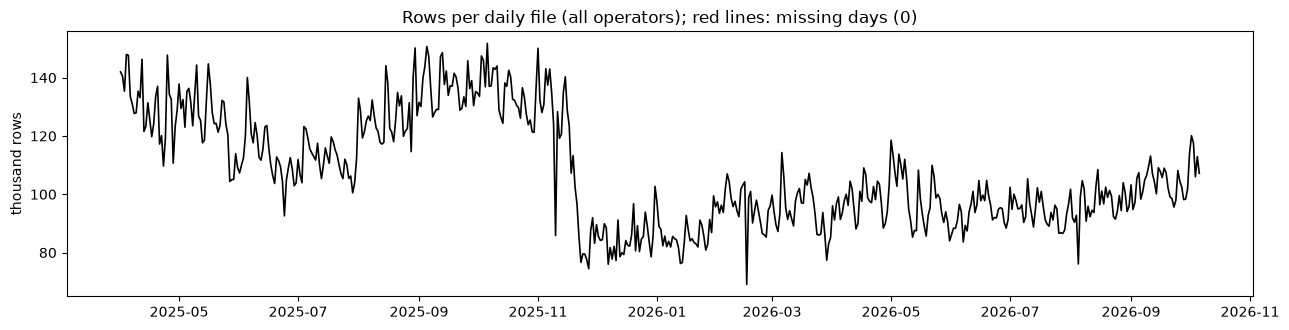

2025-04-01 to 2026-10-06: 554 files, 0 missing days


In [42]:
rows = gaming.daily_rows()
fig, ax = plt.subplots(figsize=(13, 3.4))
plots.daily_rows(rows, ax)
plt.tight_layout()
plt.show()
print(f"{rows.index.min():%Y-%m-%d} to {rows.index.max():%Y-%m-%d}: {rows.notna().sum()} files, {int(rows.isna().sum())} missing days")

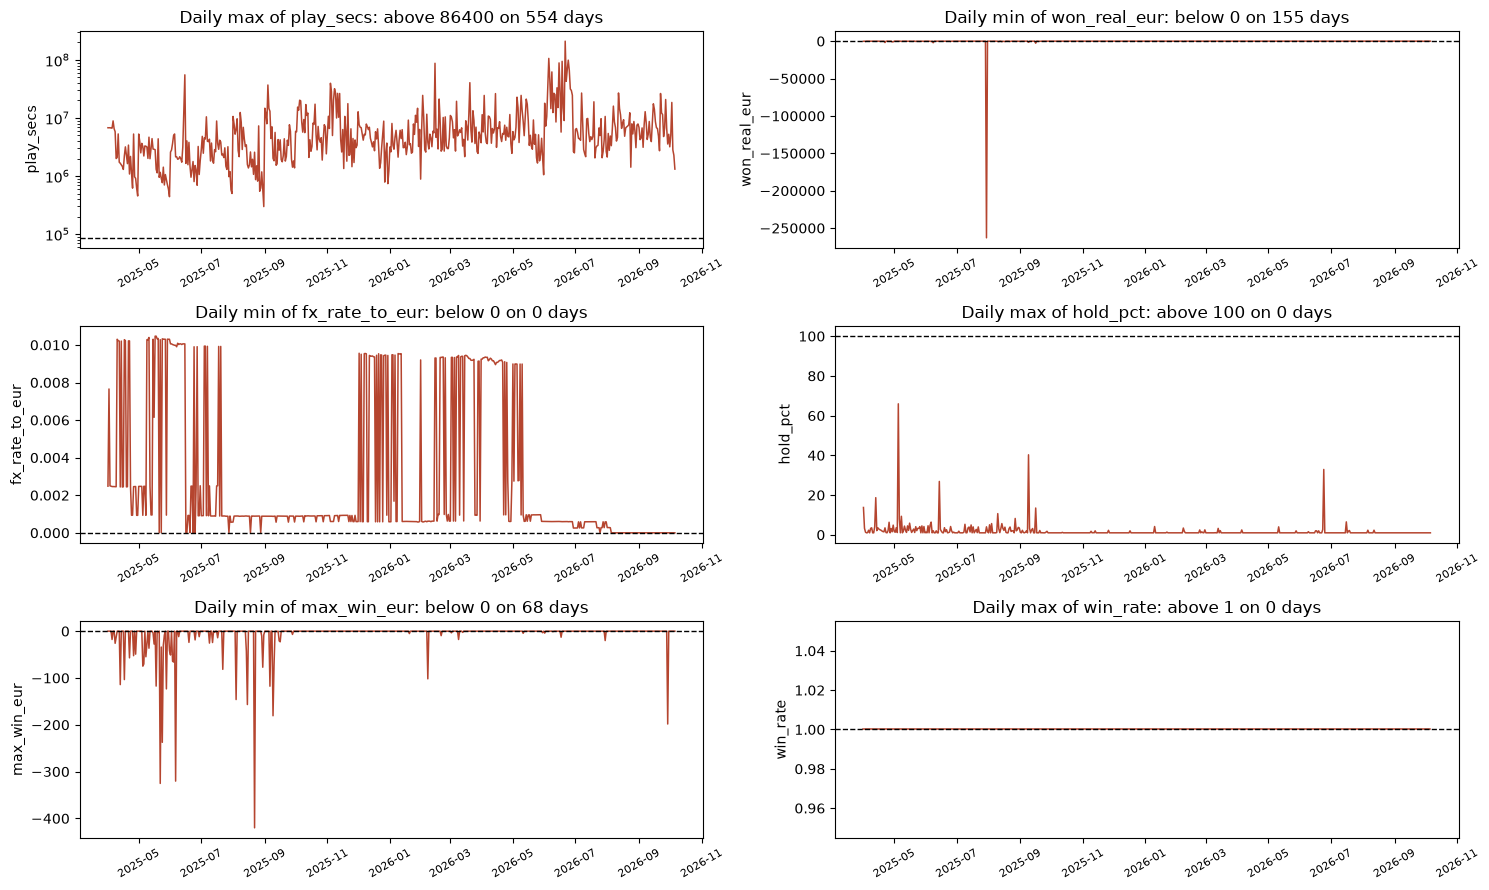

In [43]:
LIMITS = {"play_secs": ("max", 86400), "won_real_eur": ("min", 0), "fx_rate_to_eur": ("min", 0),
          "hold_pct": ("max", 100), "max_win_eur": ("min", 0), "win_rate": ("max", 1)}
ext = gaming.daily_extremes(list(LIMITS))
fig, axes = plt.subplots(3, 2, figsize=(15, 9))
plots.daily_extremes(ext, list(LIMITS), LIMITS, axes.flat)
plt.tight_layout()
plt.show()

## 3. Keys and Versions

On the raw files, before keeping the latest version of each row: rows, distinct keys, keys with copies or with more than one version, and players in more than one brand or currency on the same day.

In [44]:
keys = gaming.key_check(cfg)
display(keys.groupby("brand_id")[["rows", "keys", "keys_with_copies", "keys_with_versions"]].sum())
display(keys.groupby("day")[["players_in_2_brands", "players_in_2_currencies"]].first().describe().round(1))

,rows,keys,keys_with_copies,keys_with_versions
brand_id,,,,
14,240492.0,240492,0.0,0.0
23,916073.0,916073,0.0,0.0
64,285944.0,285944,0.0,0.0
72,343373.0,343373,0.0,0.0
73,662054.0,662054,0.0,0.0


,players_in_2_brands,players_in_2_currencies
count,30.0,30.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


## 4. Row Checks

Each check of `gaming.yaml` on the latest version of each row. **workbook** = a formula or rule of the workbook; **hypothesis** = a column the workbook does not describe, so I test a guess (for `turnover_eur` and `payout_eur` several guesses: the one that passes is the real definition).

A check **passes** if 99% of the rows pass (within 0.01 + 0.1%), is **almost** right from 95%, and **fails** below. *higher %* / *lower %*: rows where the column is above / below the expected value.

In [45]:
checks = gaming.row_checks(cfg)
summary = gaming.checks_summary(checks)
display(summary[["check", "source", "rows", "pass %", "higher %", "lower %", "days failing", "verdict", "note"]].round(2))

,check,source,rows,pass %,higher %,lower %,days failing,verdict,note
0,wagered_real_eur = wagered_real * fx_rate_to_eur,workbook,2447936,100.00,0.00,0.00,0,passes,
1,wagered_released_bonus_eur = wagered_released_bonus * fx_rate_to_eur,workbook,2447936,100.00,0.00,0.00,0,passes,
2,wagered_playable_bonus_eur = wagered_playable_bonus * fx_rate_to_eur,workbook,2447936,100.00,0.00,0.00,0,passes,
3,won_real_eur = won_real * fx_rate_to_eur,workbook,2447936,100.00,0.00,0.00,0,passes,
4,won_released_bonus_eur = won_released_bonus * fx_rate_to_eur,workbook,2447936,100.00,0.00,0.00,0,passes,
5,won_playable_bonus_eur = won_playable_bonus * fx_rate_to_eur,workbook,2447936,100.00,0.00,0.00,0,passes,
6,tax_real_eur = tax_real * fx_rate_to_eur,workbook,2447936,100.00,0.00,0.00,0,passes,
7,bets = bet_count_real + bet_count_released_bonus + bet_count_playable_bonus,workbook,2447936,78.45,0.43,21.12,30,fails,
8,turnover_eur = wagered_real_eur + wagered_released_bonus_eur + wagered_playable_bonus_eur,hypothesis,2447936,100.00,0.00,0.00,0,passes,all wallets
9,turnover_eur = wagered_real_eur + wagered_released_bonus_eur,hypothesis,2447936,72.77,27.23,0.00,30,rejected,real and released bonus


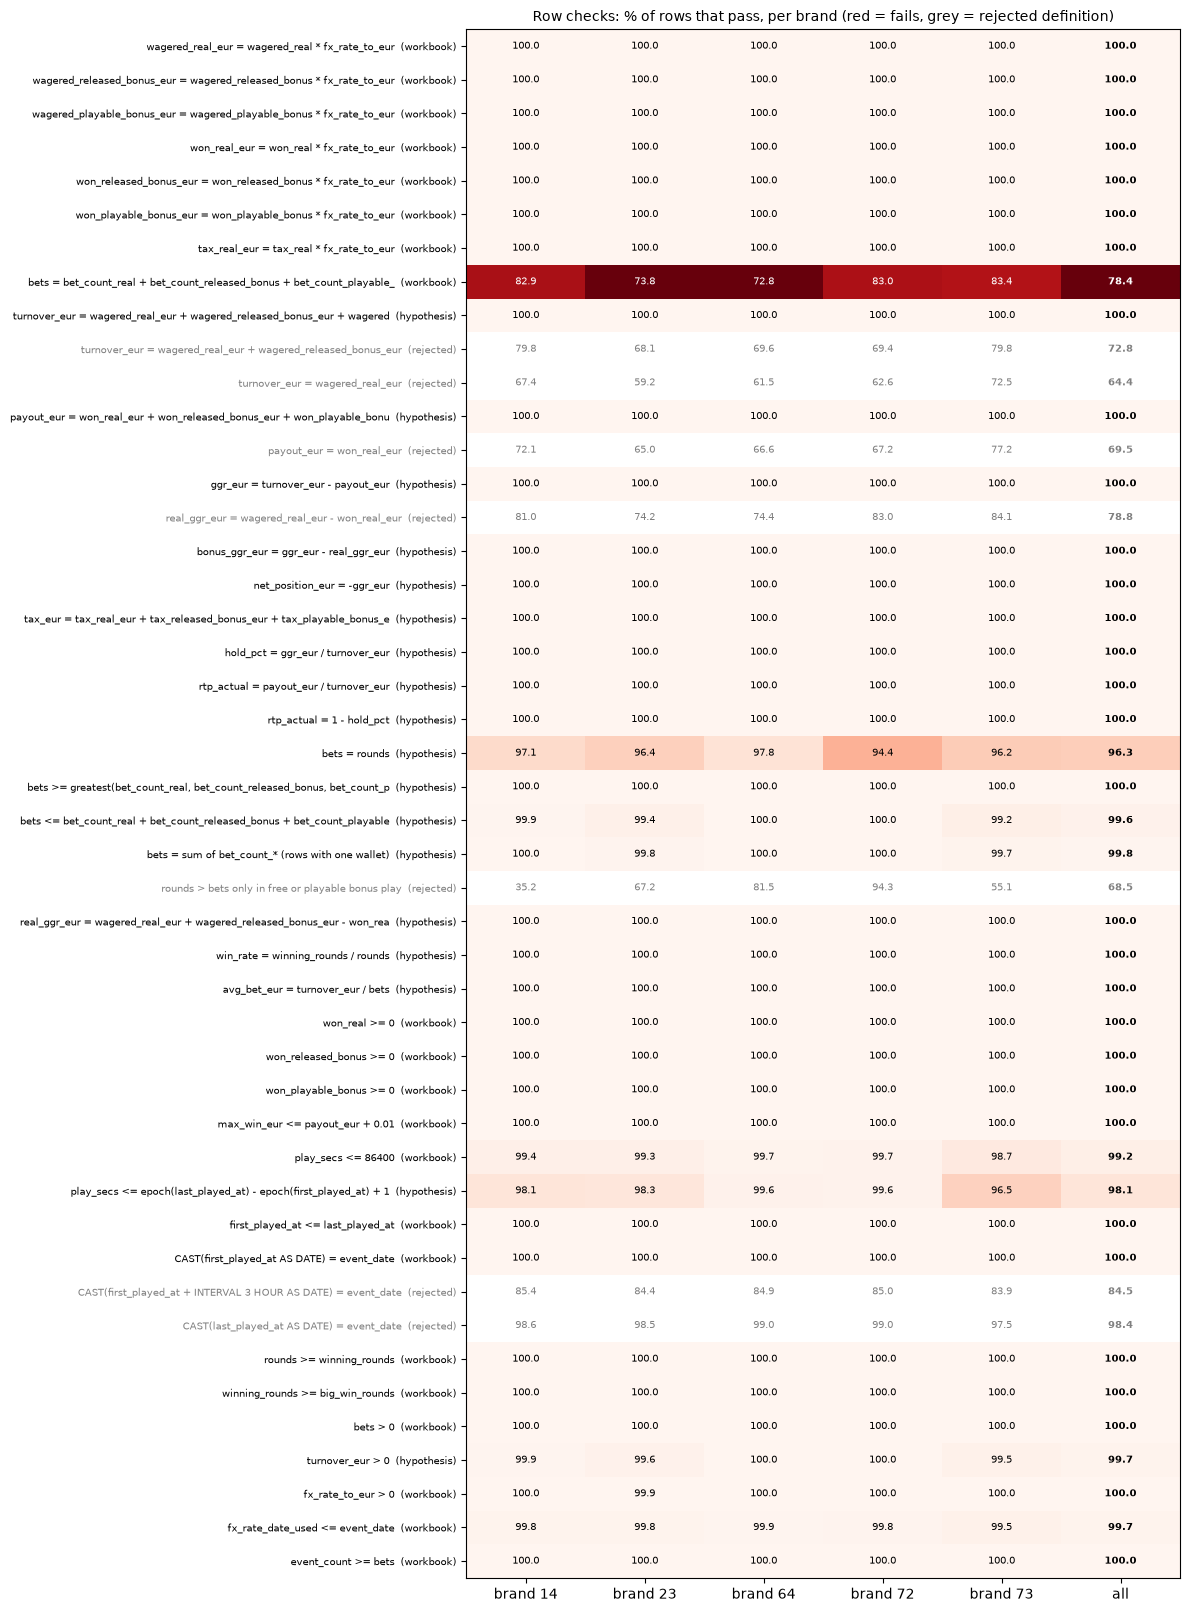

In [46]:
fig, ax = plt.subplots(figsize=(12, 0.32 * len(summary) + 1.5))
plots.checks_heatmap(summary, ax)
plt.tight_layout()
plt.show()

**Failing checks by day:** a check that fails every day is a definition problem; one that fails on some days is a data problem.

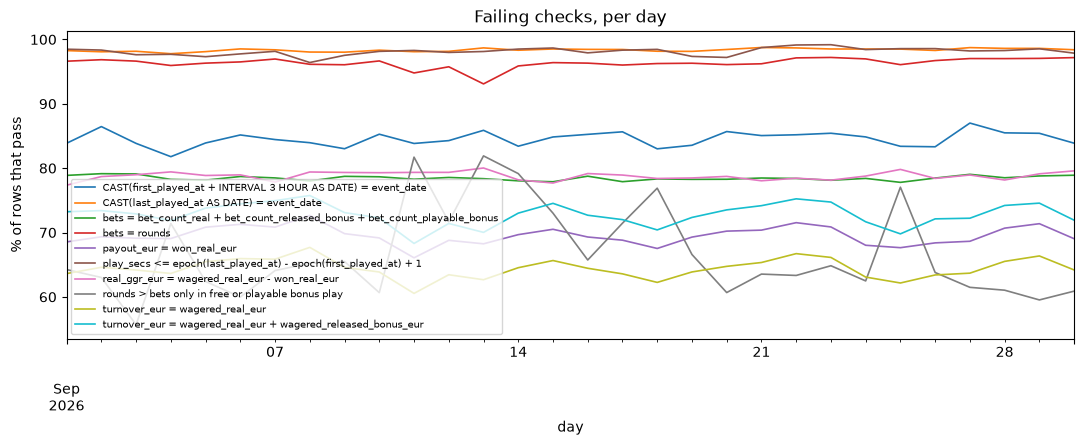

In [47]:
bad = summary.loc[summary["verdict"] != "passes", "check"]
daily = checks[checks["check"].isin(bad)].groupby(["check", "day"])[["n", "ok"]].sum()
daily = (100 * daily["ok"] / daily["n"]).unstack("check")
if not daily.empty:
    ax = daily.plot(figsize=(13, 4), lw=1.2)
    ax.set(ylabel="% of rows that pass", title="Failing checks, per day")
    ax.legend(fontsize=7)
    plt.show()

**Other definitions.** When a check does not pass, I test other definitions of the same thing (`group` in `gaming.yaml`). A hypothesis is **rejected** when another check of its group passes: it is the definition that the table does not use, not an error.

- **`bets`:** a bet paid from two wallets may count once in `bets` but once in each `bet_count_*`. If so, `max(bet_count_*) <= bets <= sum` holds, and `bets = sum` holds in the rows with one wallet.
- **`rounds > bets`:** the extra rounds should be free rounds (no stake) or playable bonus rounds.
- **`event_date`:** the day of the first play in UTC, in Turkish time (UTC+3), or the day of the last play (settlement).

In [48]:
alt = summary[summary["group"].isin(["bets", "bets_split", "bets_one_wallet", "event_day"]) | (summary["column"] == "rounds")]
display(alt[["check", "source", "rows", "pass %", "higher %", "lower %", "verdict", "note"]].style.format(precision=2).hide(axis="index"))

check,source,rows,pass %,higher %,lower %,verdict,note
bets = bet_count_real + bet_count_released_bonus + bet_count_playable_bonus,workbook,2447936,78.45,0.43,21.12,fails,
bets = rounds,hypothesis,2447936,96.32,1.53,2.15,almost,"bets counts rounds, not bet transactions"
"bets >= greatest(bet_count_real, bet_count_released_bonus, bet_count_playable_bonus)",hypothesis,2447936,100.00,0.00,0.00,passes,a bet paid from two wallets counts once in bets
bets <= bet_count_real + bet_count_released_bonus + bet_count_playable_bonus,hypothesis,2447936,99.57,0.00,0.00,passes,and once in the count of each wallet
bets = sum of bet_count_* (rows with one wallet),hypothesis,1785268,99.85,0.15,0.00,passes,no bet split between wallets
rounds > bets only in free or playable bonus play,hypothesis,52914,68.54,0.00,0.00,rejected,a round with no bet is a free or bonus round
CAST(first_played_at AS DATE) = event_date,workbook,2447936,100.00,0.00,0.00,passes,the first play is on the day of the row
CAST(first_played_at + INTERVAL 3 HOUR AS DATE) = event_date,hypothesis,2447936,84.52,0.00,0.00,rejected,event_date is the Turkish day (UTC+3)
CAST(last_played_at AS DATE) = event_date,hypothesis,2447936,98.35,0.00,0.00,rejected,event_date is the day of the last play (settlement)
rounds >= winning_rounds,workbook,2447936,100.00,0.00,0.00,passes,


**Hour of the first play.** Rows per UTC hour of the first play. If the rows on another day than `event_date` pile up in a few hours (for example 21:00 to 24:00), `event_date` uses another time zone; if they are spread over the day, a row can join plays of two days.

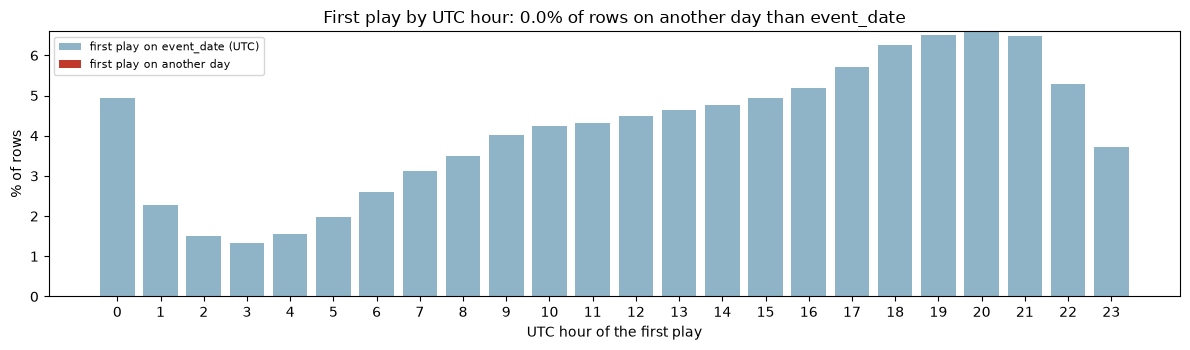

days from first play to event_date (% of rows),0
brand_id,
14,100.0
23,100.0
64,100.0
72,100.0
73,100.0


In [49]:
hours = gaming.first_play_hours(cfg)
fig, ax = plt.subplots(figsize=(12, 3.6))
plots.first_play_hours(hours, ax)
plt.tight_layout(); plt.show()
shift = hours.groupby(["brand_id", "day_shift"])["rows"].sum().unstack(fill_value=0)
display((100 * shift.div(shift.sum(axis=1), axis=0)).round(2).rename_axis(columns="days from first play to event_date (% of rows)"))

## 5. Distributions

The scorecard of notebook 01 for this table: rows, median, 99th percentile, share outside the real-life range, peaks and the fit of the expected family. Metrics `row_*` are one row of the table; `pd_*` are one player and day (all games together).

In [50]:
profiles, results, card = {}, {}, []
for name in list(METRICS):
    prof, hist = audit.metric_data(cfg, name)
    if prof["n"] == 0:                      # no row matches the metric: nothing to fit or plot
        print(f"{name}: no rows")
        METRICS.remove(name)
        continue
    res = stats.fit(cfg, name, prof, hist)
    profiles[name], results[name] = prof, res
    card.append(stats.summary_row(cfg, name, prof, res))
scorecard = pd.DataFrame(card).set_index("metric")
scorecard.style.format({"rows": "{:,}", "null %": "{:.1f}", "p1": "{:.3g}", "median": "{:.3g}", "p99": "{:.3g}",
                        "max": "{:.3g}", "outside range %": "{:.2f}", "KS distance": "{:.3f}"})

,table,expected,rows,null %,p1,median,p99,max,outside range %,peaks,best fit,KS distance,fit
metric,,,,,,,,,,,,,
row_turnover_eur,gaming_rows,lognormal,"2,423,692",0.0,0.0358,22.1,3.37e+03,4.13e+06,0.13,1,Log-normal,0.028,close
row_bets,gaming_rows,lognormal,"2,431,214",0.0,1,51,2.08e+03,3.36e+04,0.00,1,Log-normal,0.067,acceptable
row_avg_bet_eur,gaming_rows,lognormal,"2,423,692",0.0,0.013,0.356,100,1e+05,0.81,1,Log-normal,0.078,acceptable
row_play_secs,gaming_rows,lognormal,"2,295,095",0.0,0.343,150,6.98e+04,2.64e+07,4.46,1,Log-normal,0.063,acceptable
row_hold_pct,gaming_rows,share,"2,423,692",0.0,-4.09,0.368,1,1,0.00,2,,nan,
row_rtp_actual,gaming_rows,share,"2,423,692",0.0,0,0.632,5.09,4.91e+05,0.00,2,,nan,
row_win_rate,gaming_rows,share,"2,447,936",0.0,0,0.252,1,1,0.00,2,,nan,
row_fx_rate,gaming_rows,share,"2,447,936",0.0,0.0177,0.0179,1,1,0.04,2,,nan,
row_max_win_eur,gaming_rows,lognormal,"1,798,613",0.0,0.0133,7.77,759,9.05e+05,0.84,1,Log-normal,0.033,acceptable


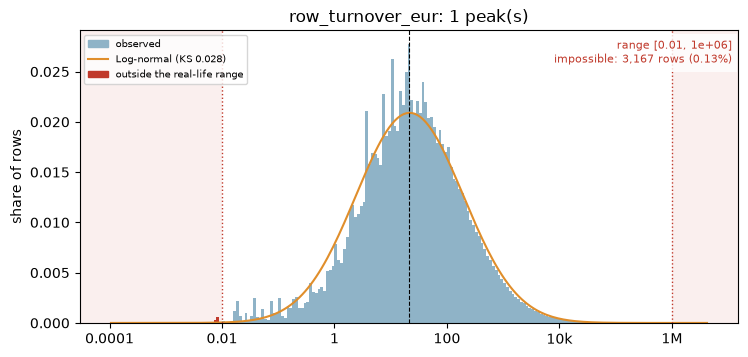

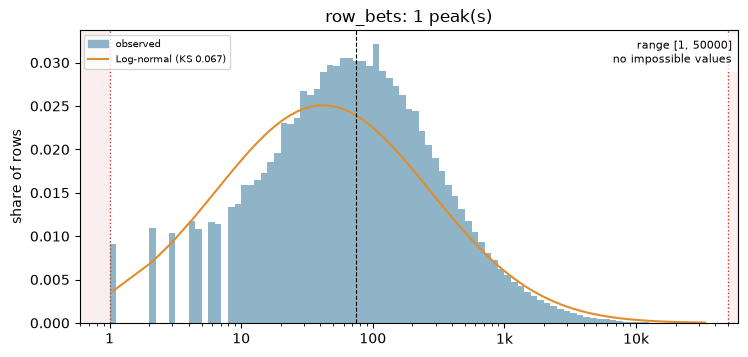

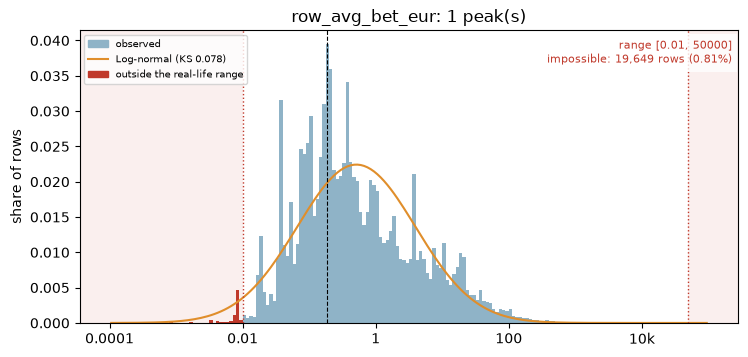

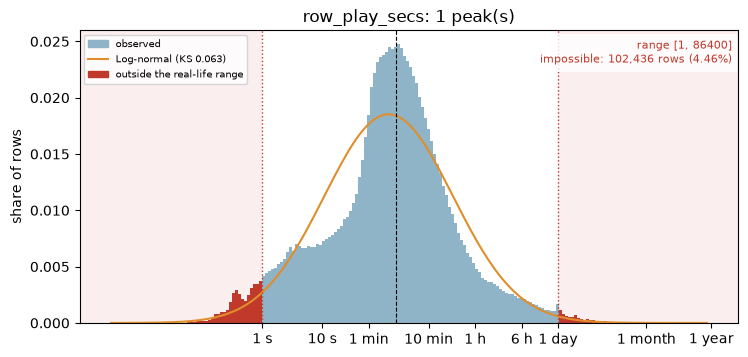

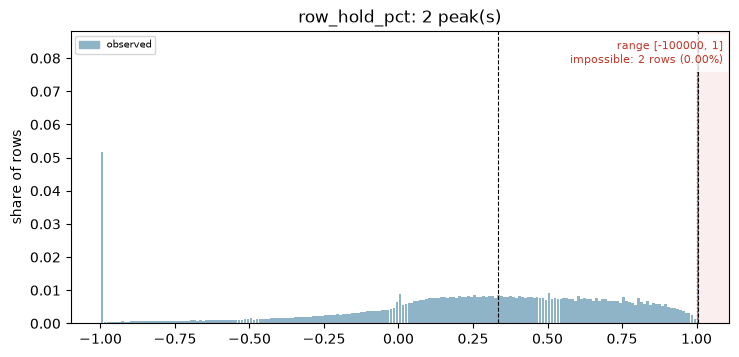

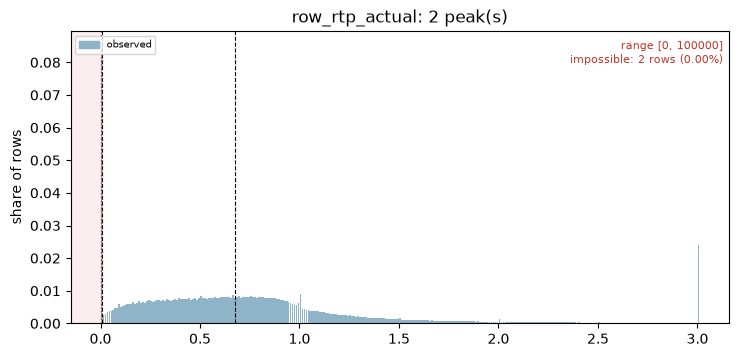

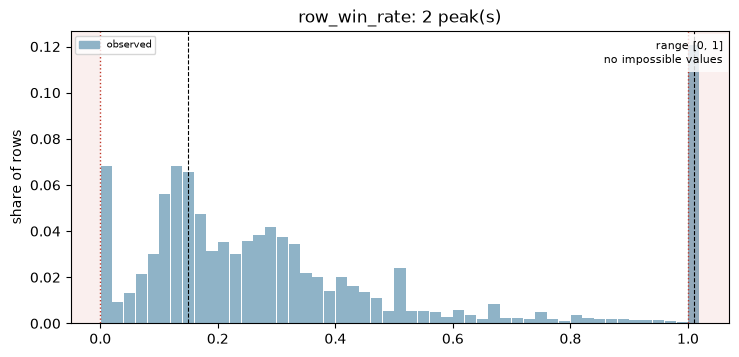

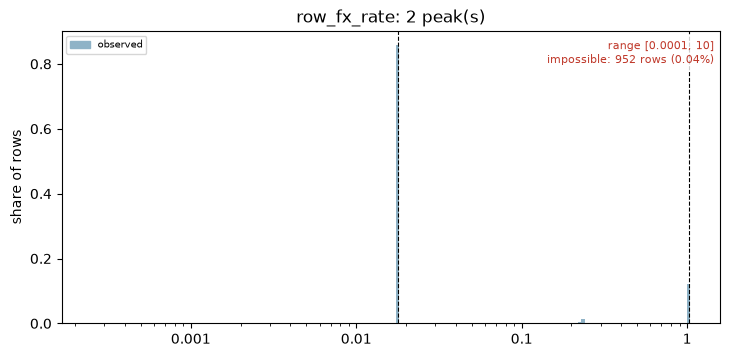

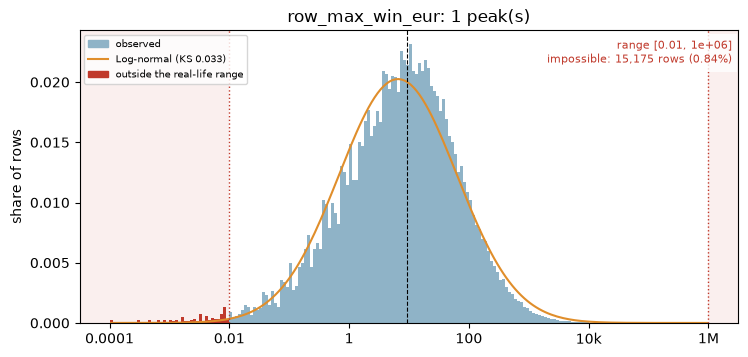

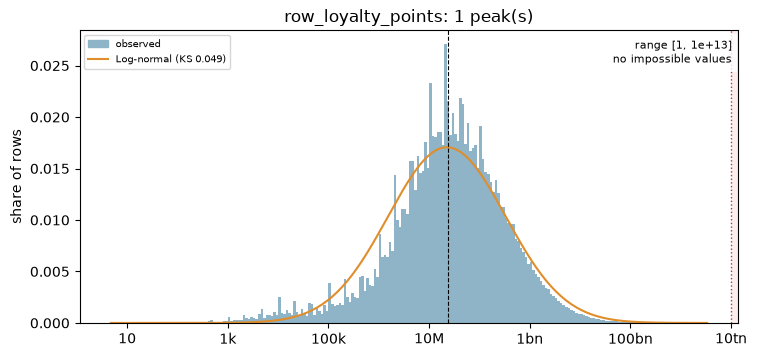

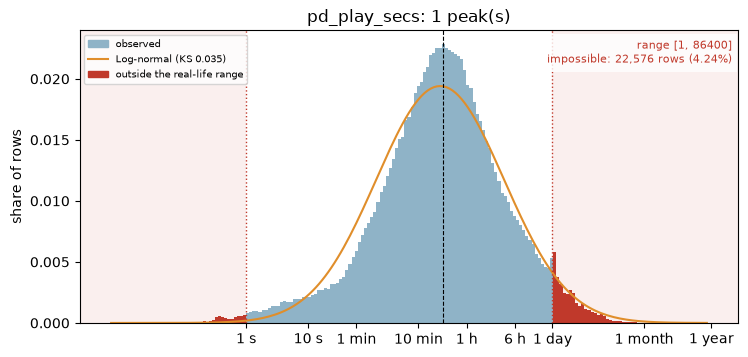

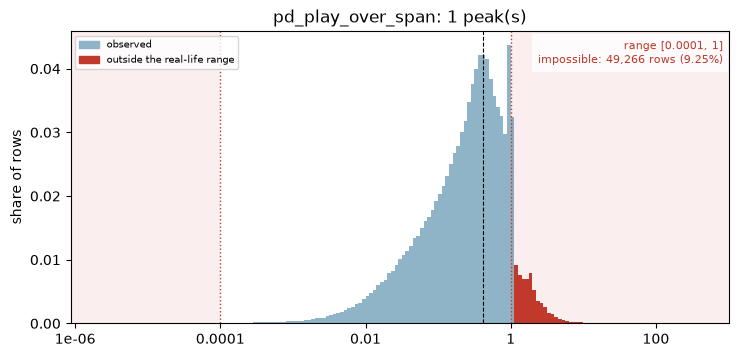

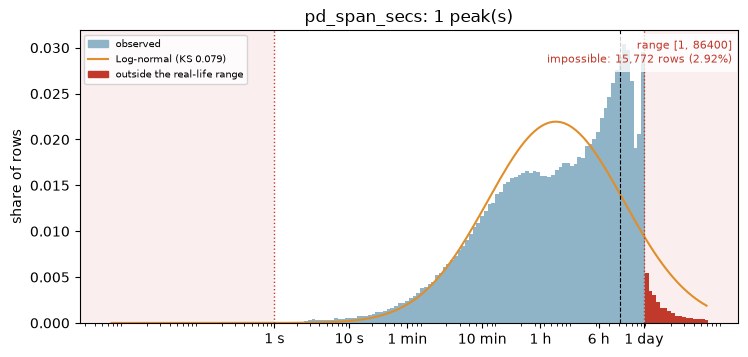

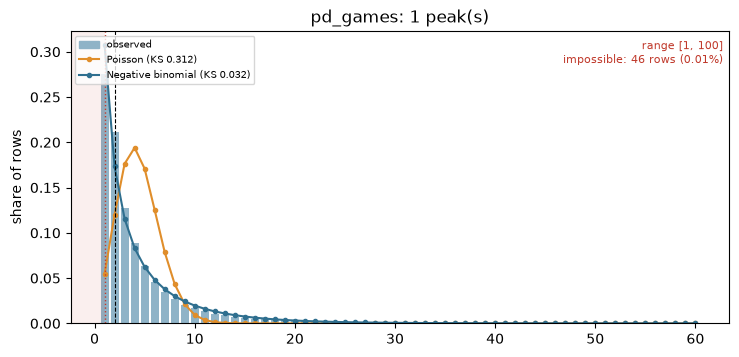

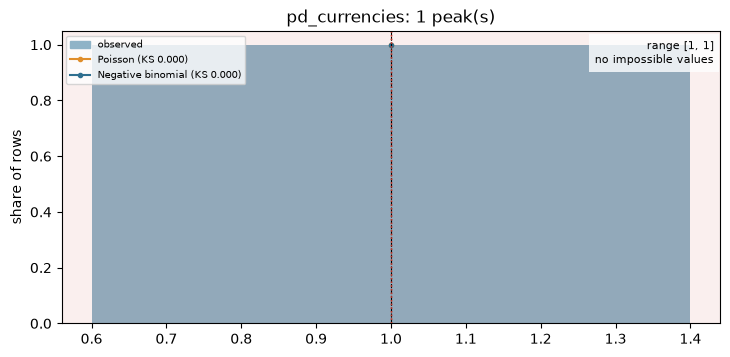

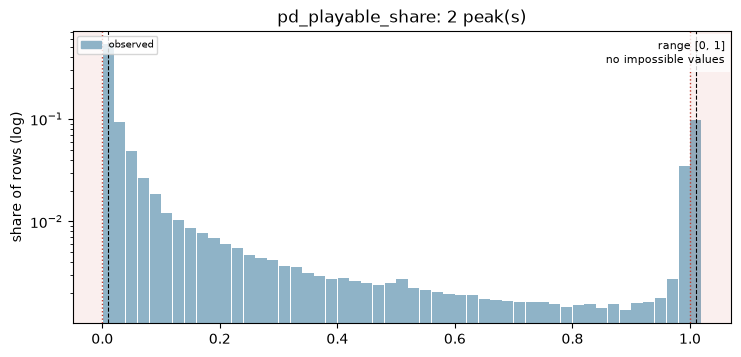

In [51]:
for name in METRICS:
    plots.metric(cfg, results[name], profiles[name])
    plt.show()

**Brand by brand:** the same scorecard per brand, and one panel per brand.

In [52]:
card_b = stats.brand_scorecard(cfg, METRICS)
display(card_b[["metric", "brand", "rows", "median", "p99", "max", "outside range %", "peaks", "best fit", "KS distance", "fit"]].round(3))

,metric,brand,rows,median,p99,max,outside range %,peaks,best fit,KS distance,fit
0,row_turnover_eur,14,240087,2.855000e+01,5.461439e+03,4.133681e+06,0.147,1,Log-normal,0.026,close
1,row_turnover_eur,23,907660,2.418500e+01,3.491246e+03,3.960398e+06,0.157,1,Log-normal,0.026,close
2,row_turnover_eur,64,284821,2.207400e+01,2.848193e+03,8.169011e+05,0.157,1,Log-normal,0.029,close
3,row_turnover_eur,72,335366,1.610200e+01,2.162377e+03,4.463098e+05,0.101,1,Log-normal,0.031,acceptable
4,row_turnover_eur,73,655758,2.168700e+01,3.215127e+03,2.002392e+06,0.091,1,Log-normal,0.029,close
5,row_bets,14,240347,5.700000e+01,2.325000e+03,2.108600e+04,0.000,1,Log-normal,0.058,acceptable
6,row_bets,23,911566,5.800000e+01,2.189000e+03,3.028500e+04,0.000,1,Log-normal,0.062,acceptable
7,row_bets,64,284900,6.300000e+01,2.180000e+03,2.008800e+04,0.000,1,Log-normal,0.060,acceptable
8,row_bets,72,335506,5.300000e+01,2.096000e+03,3.360200e+04,0.000,1,Log-normal,0.055,acceptable
9,row_bets,73,658895,3.700000e+01,1.765000e+03,3.133200e+04,0.000,1,Log-normal,0.088,different


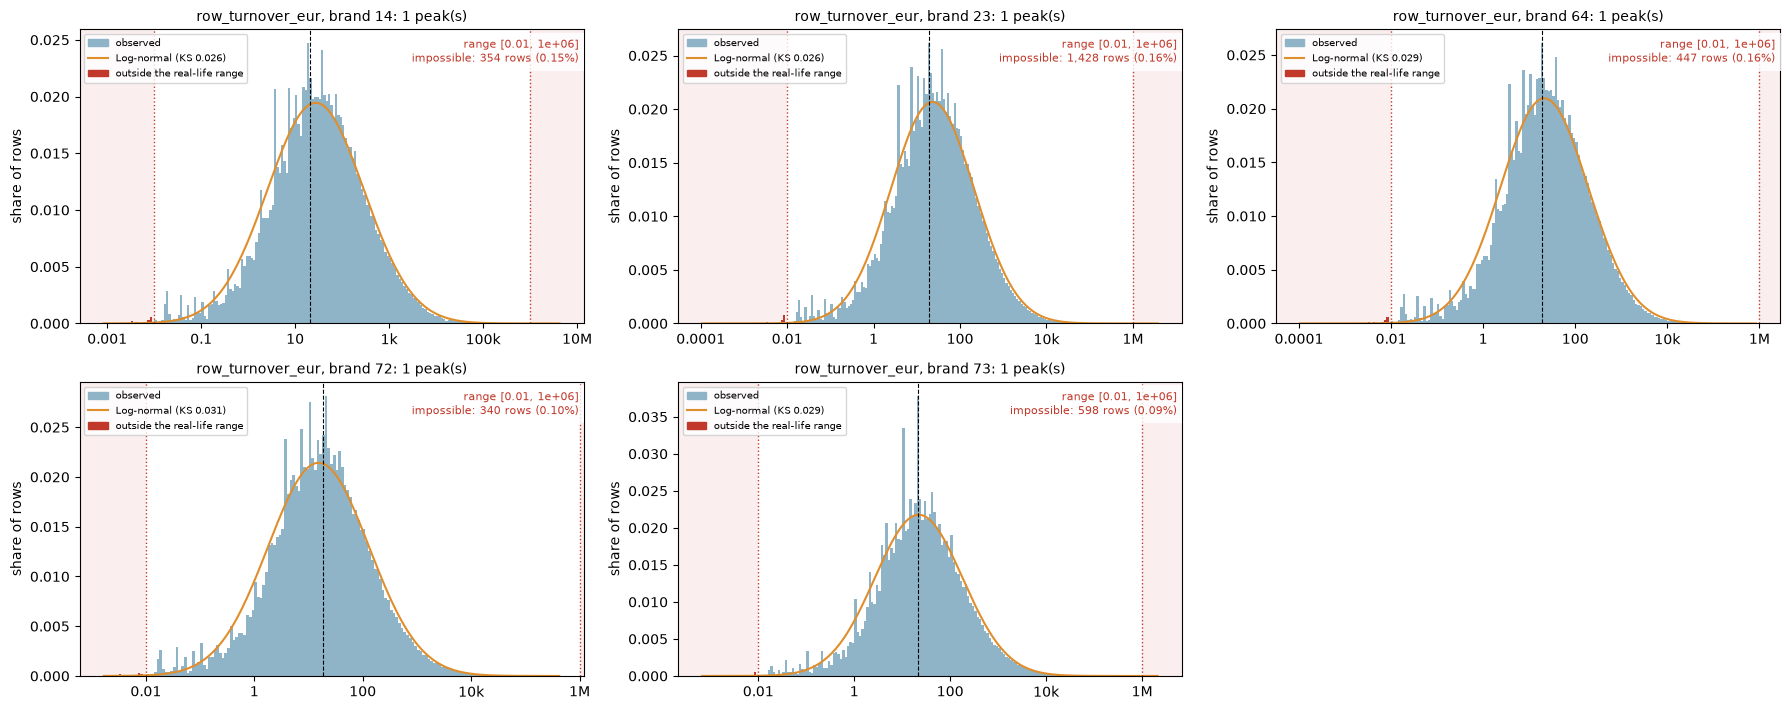

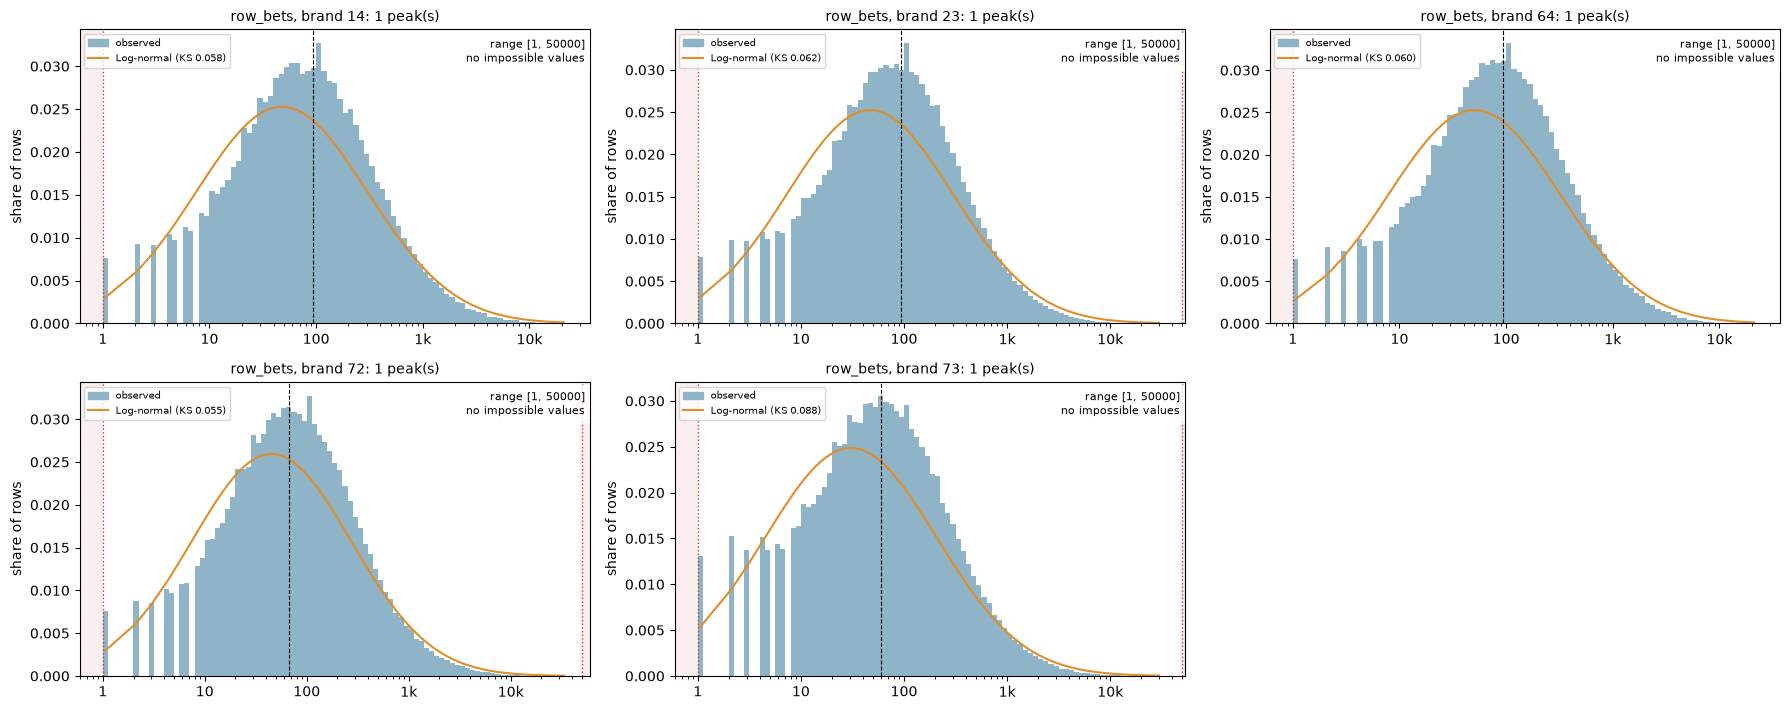

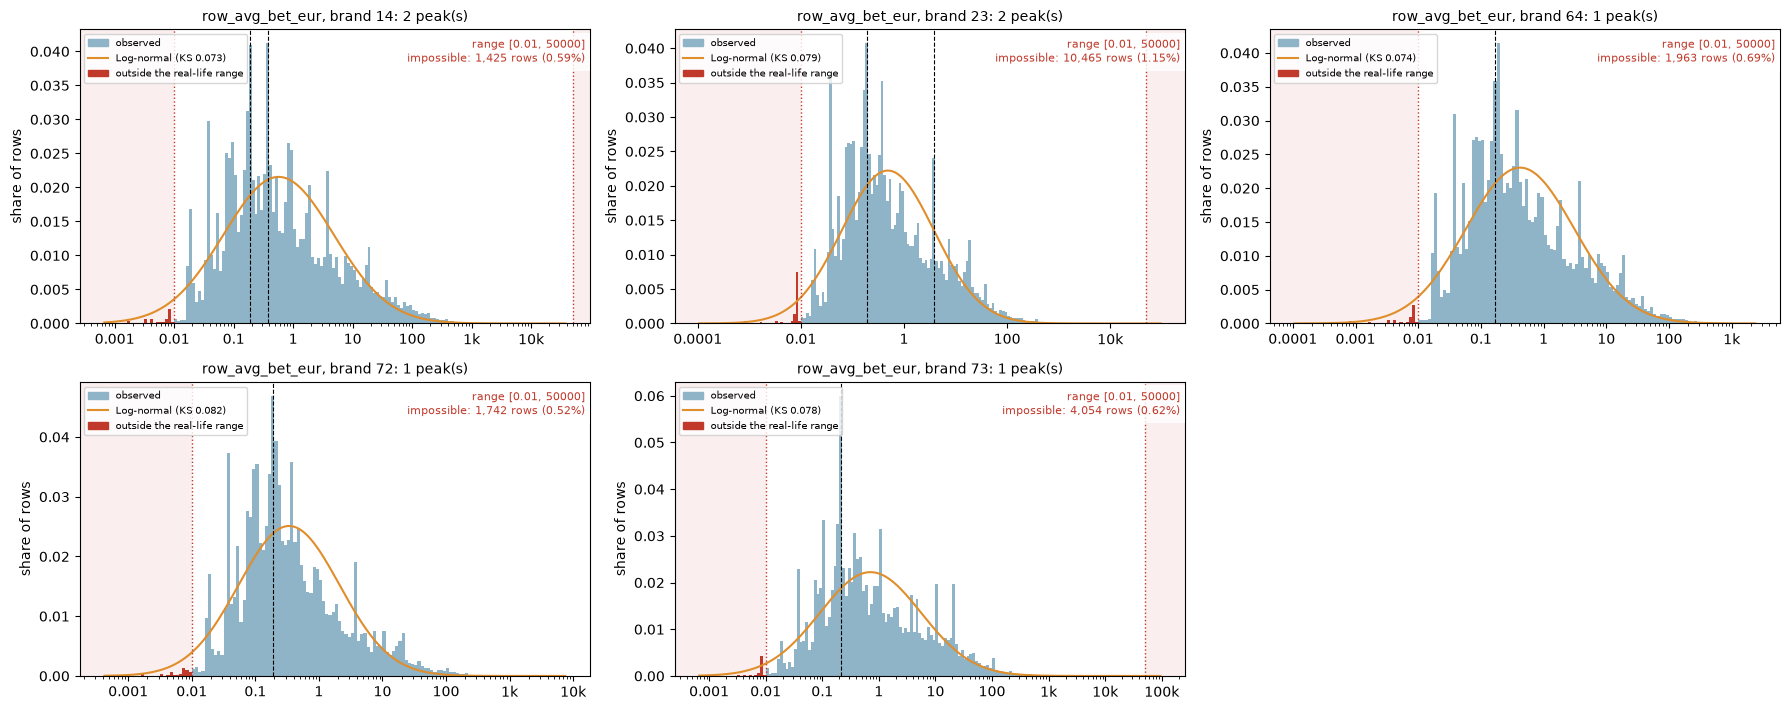

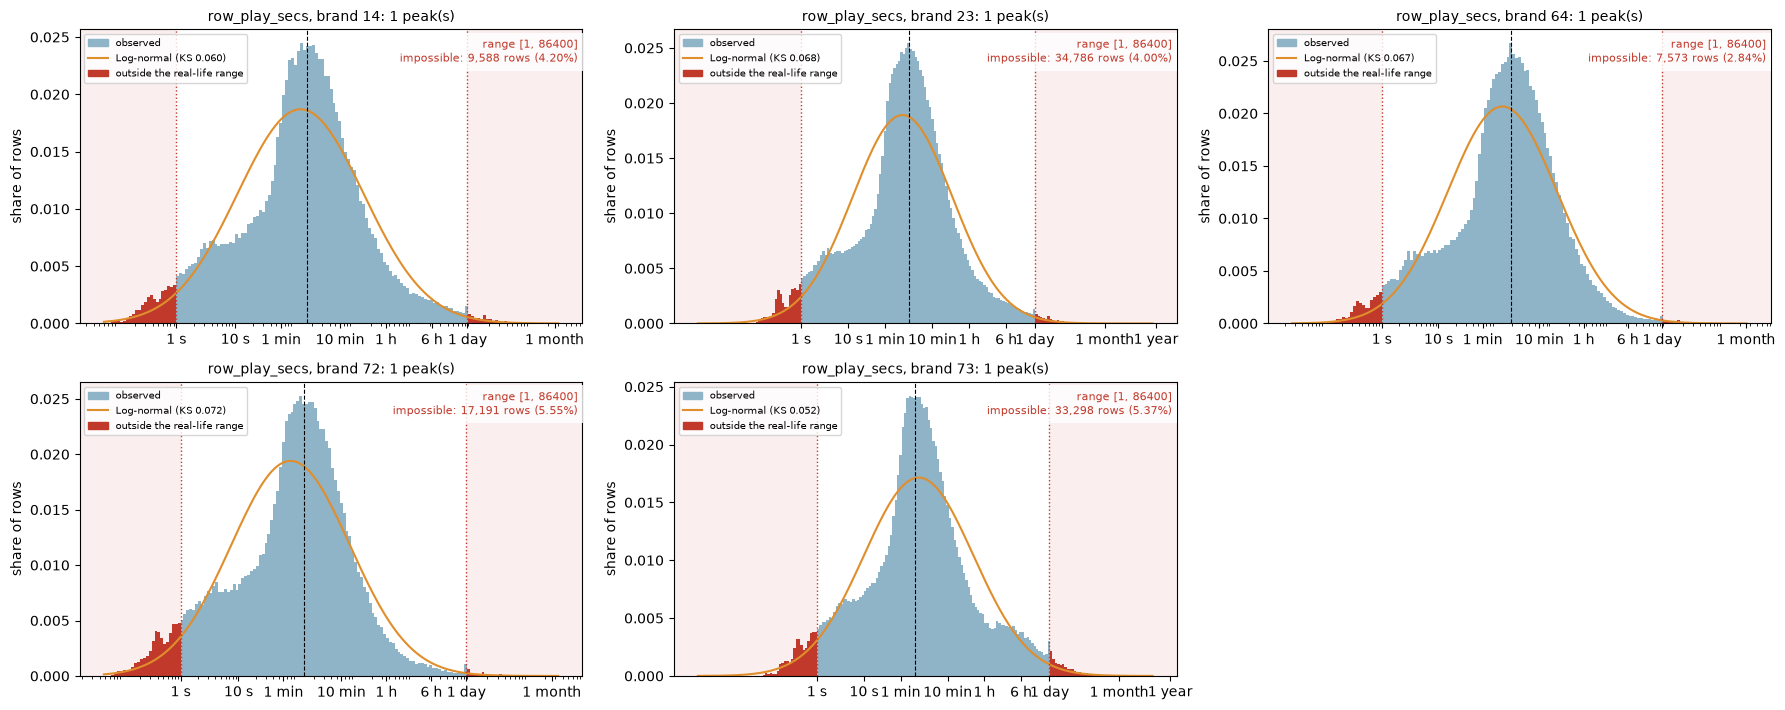

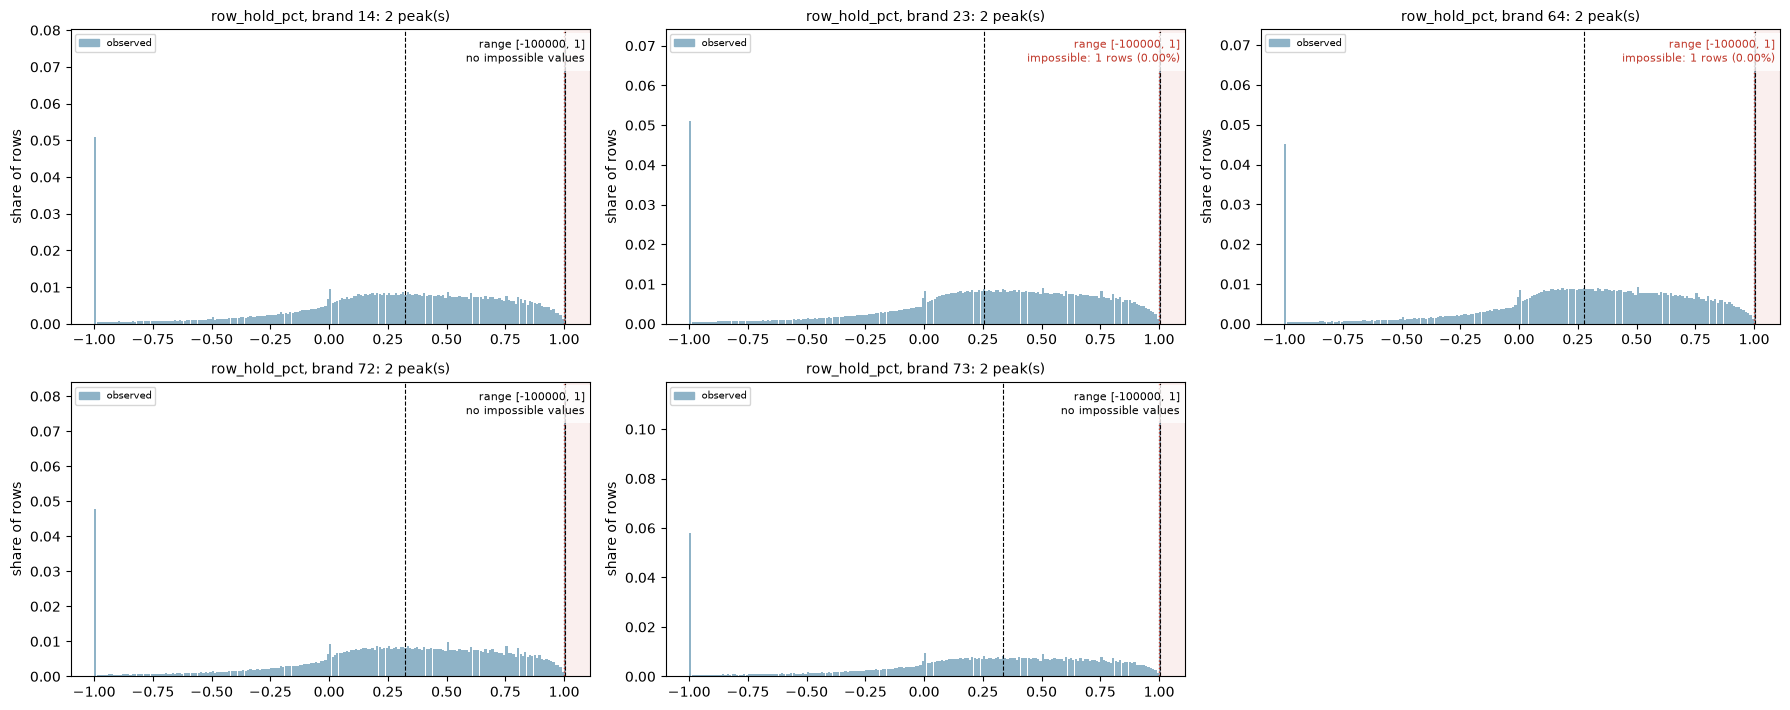

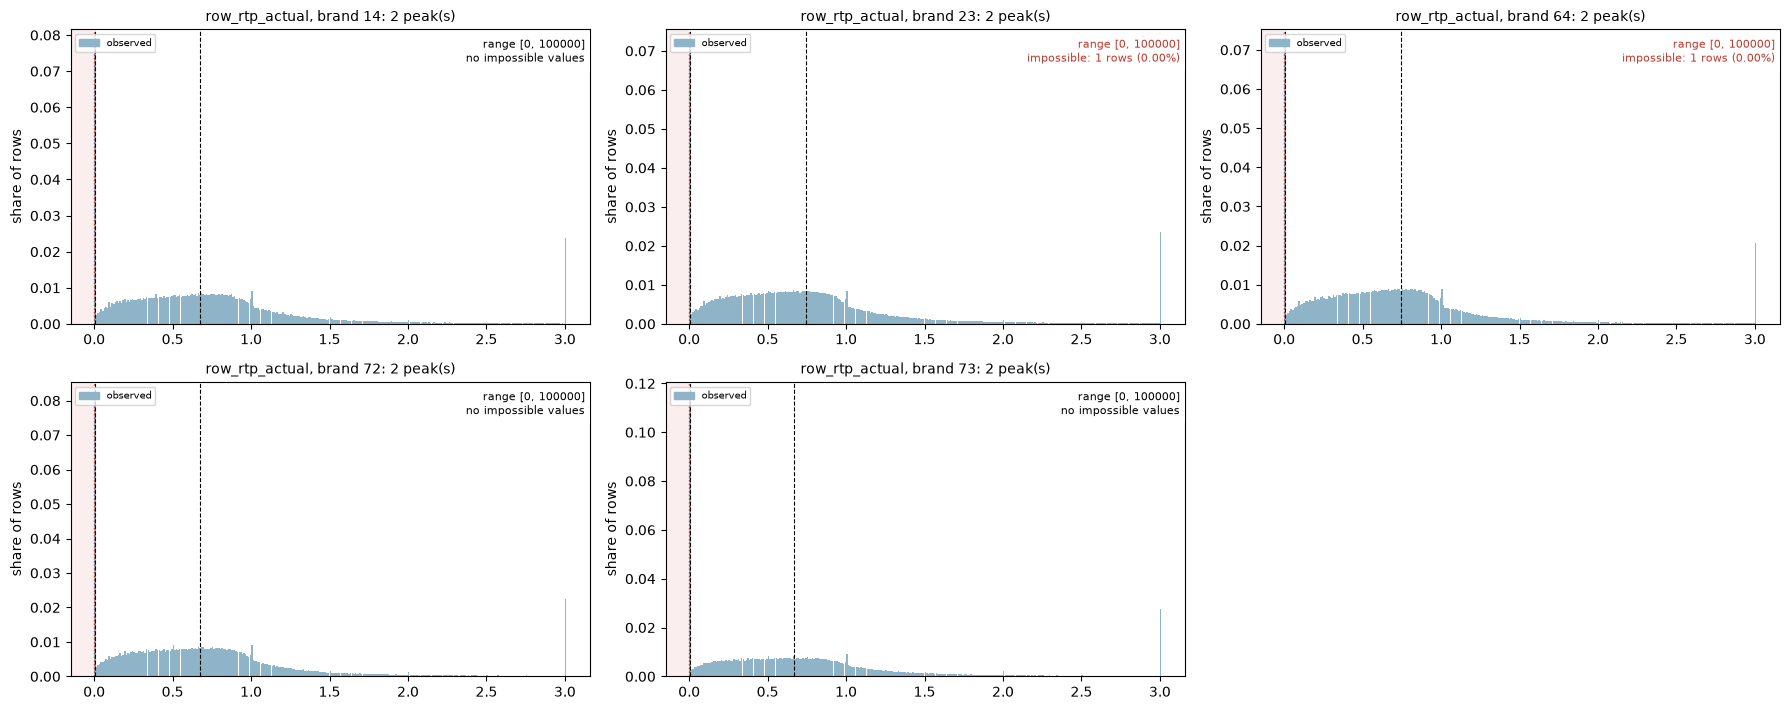

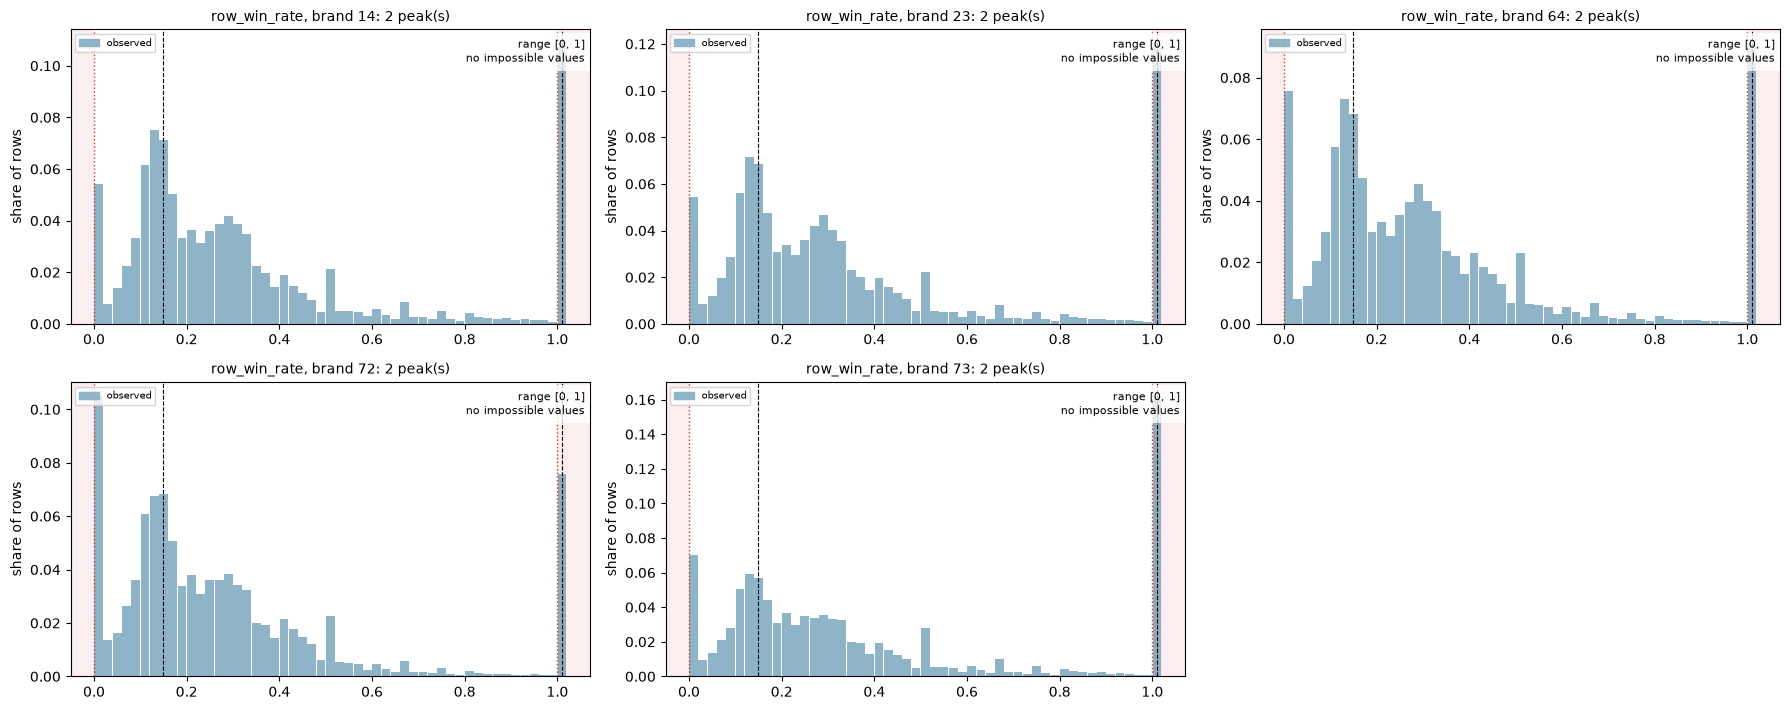

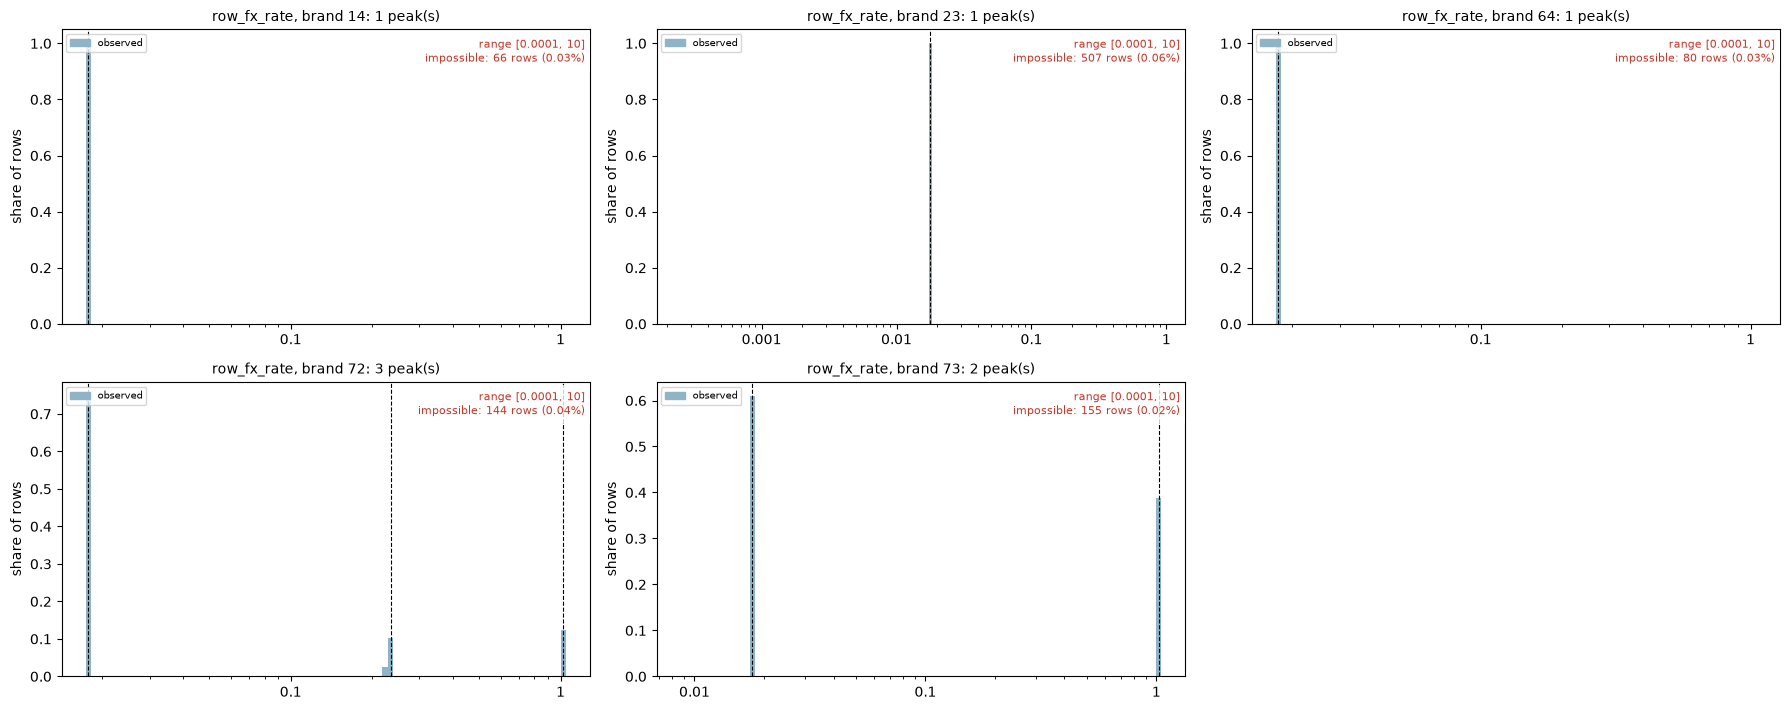

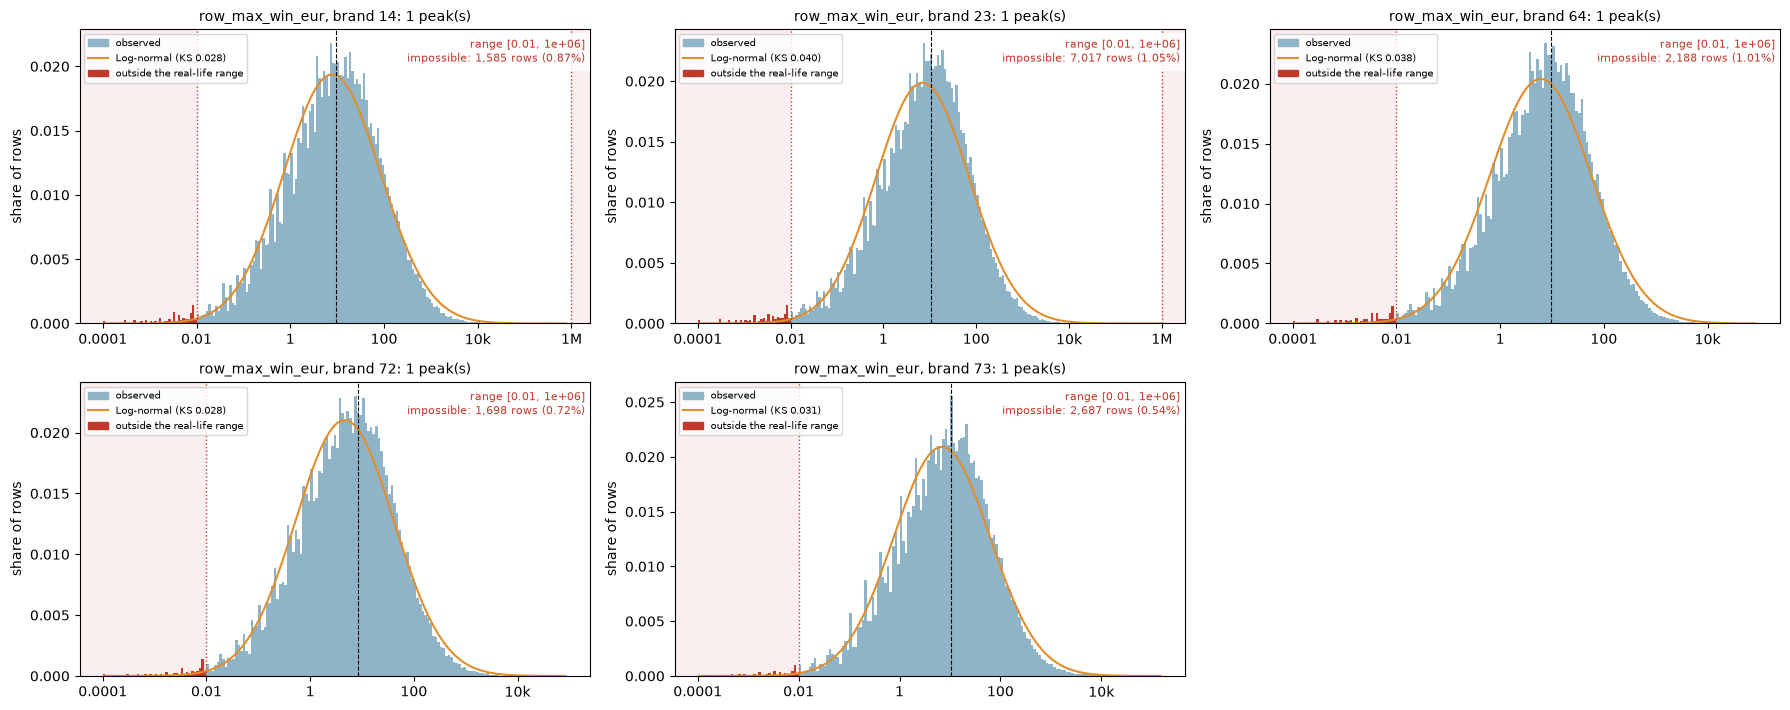

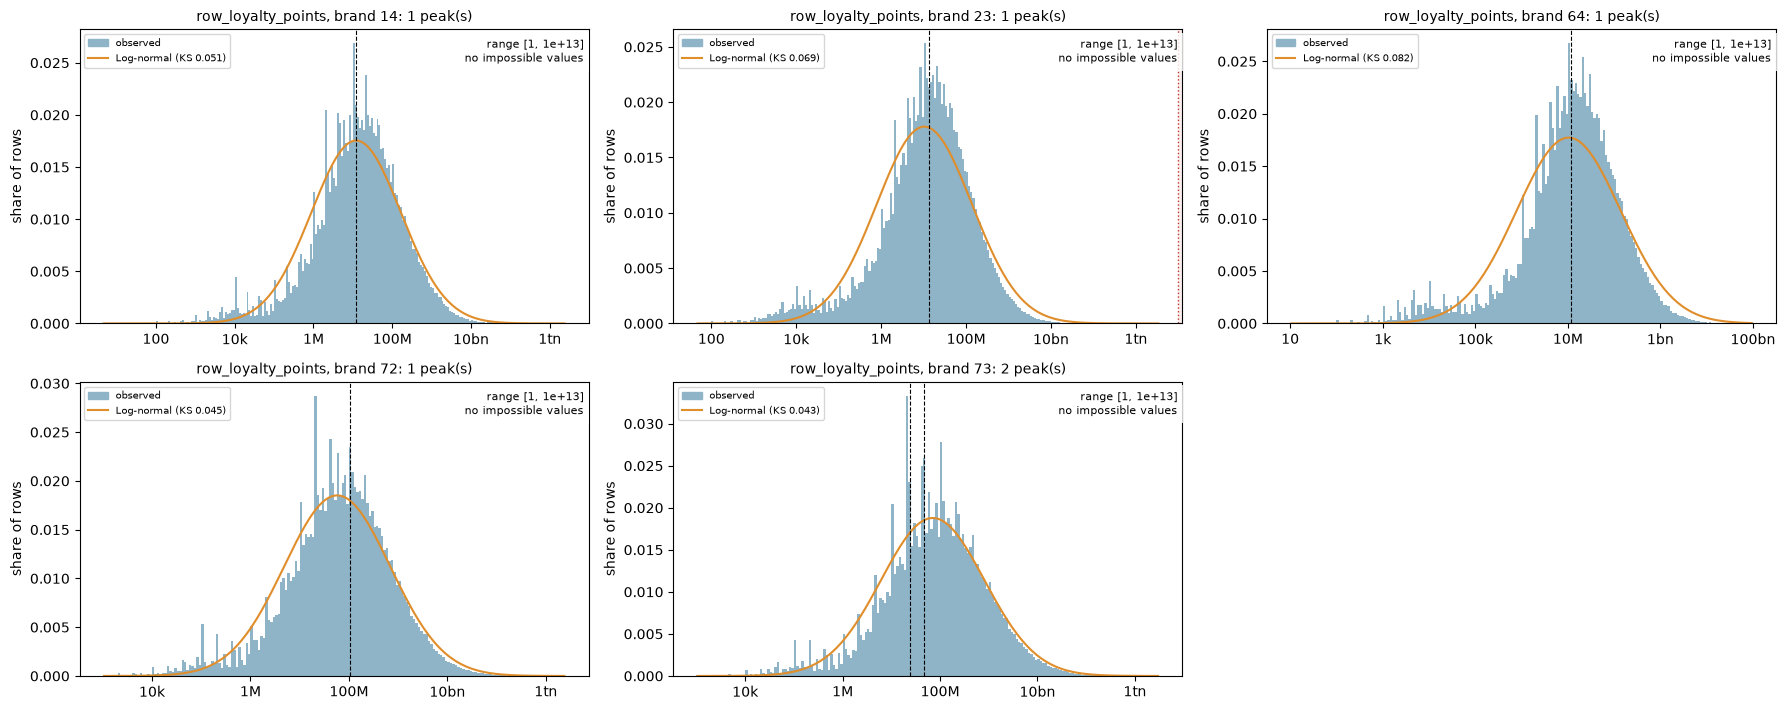

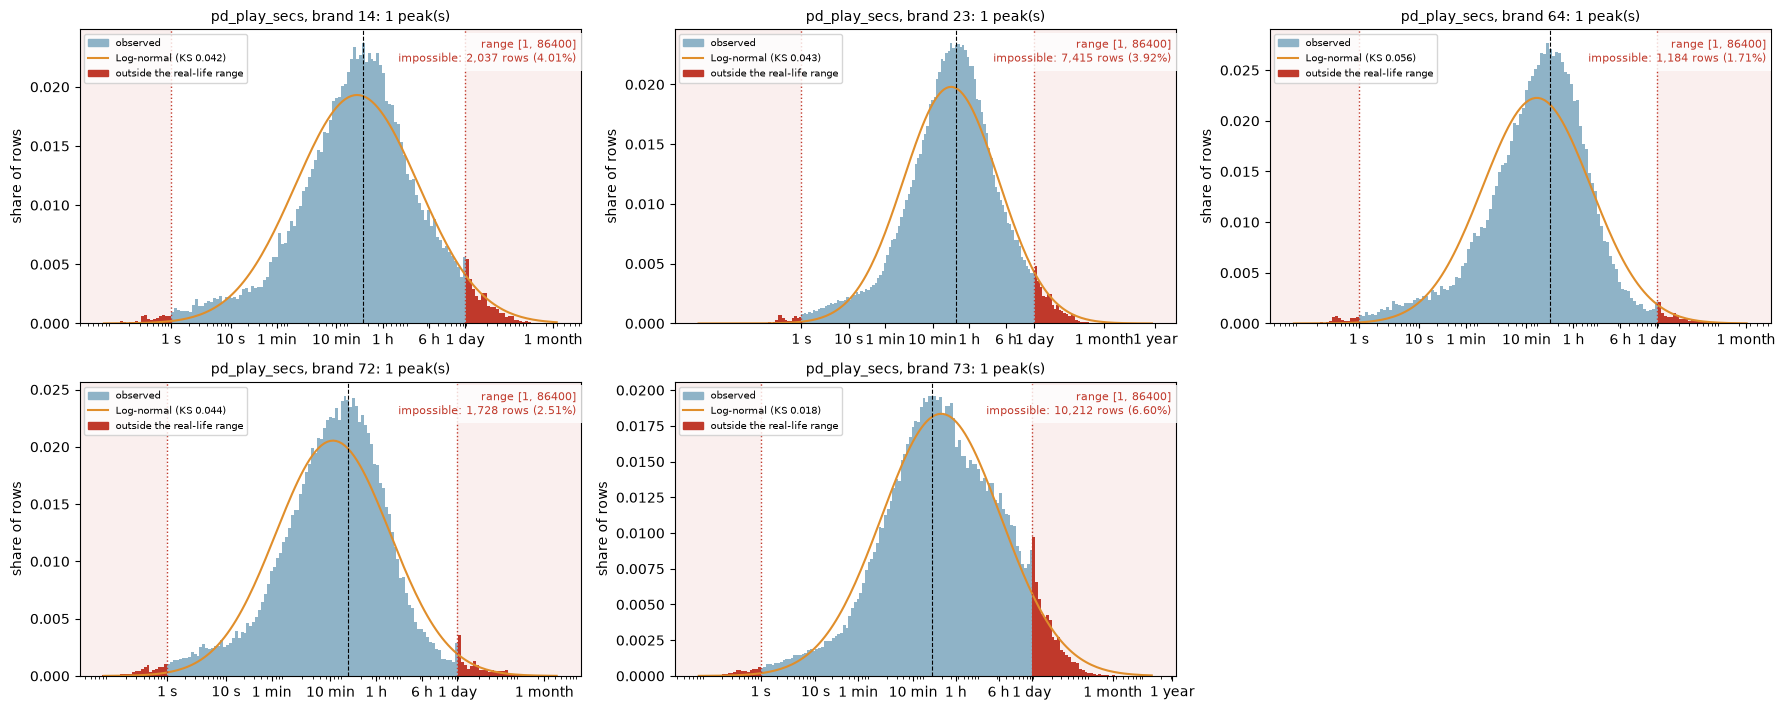

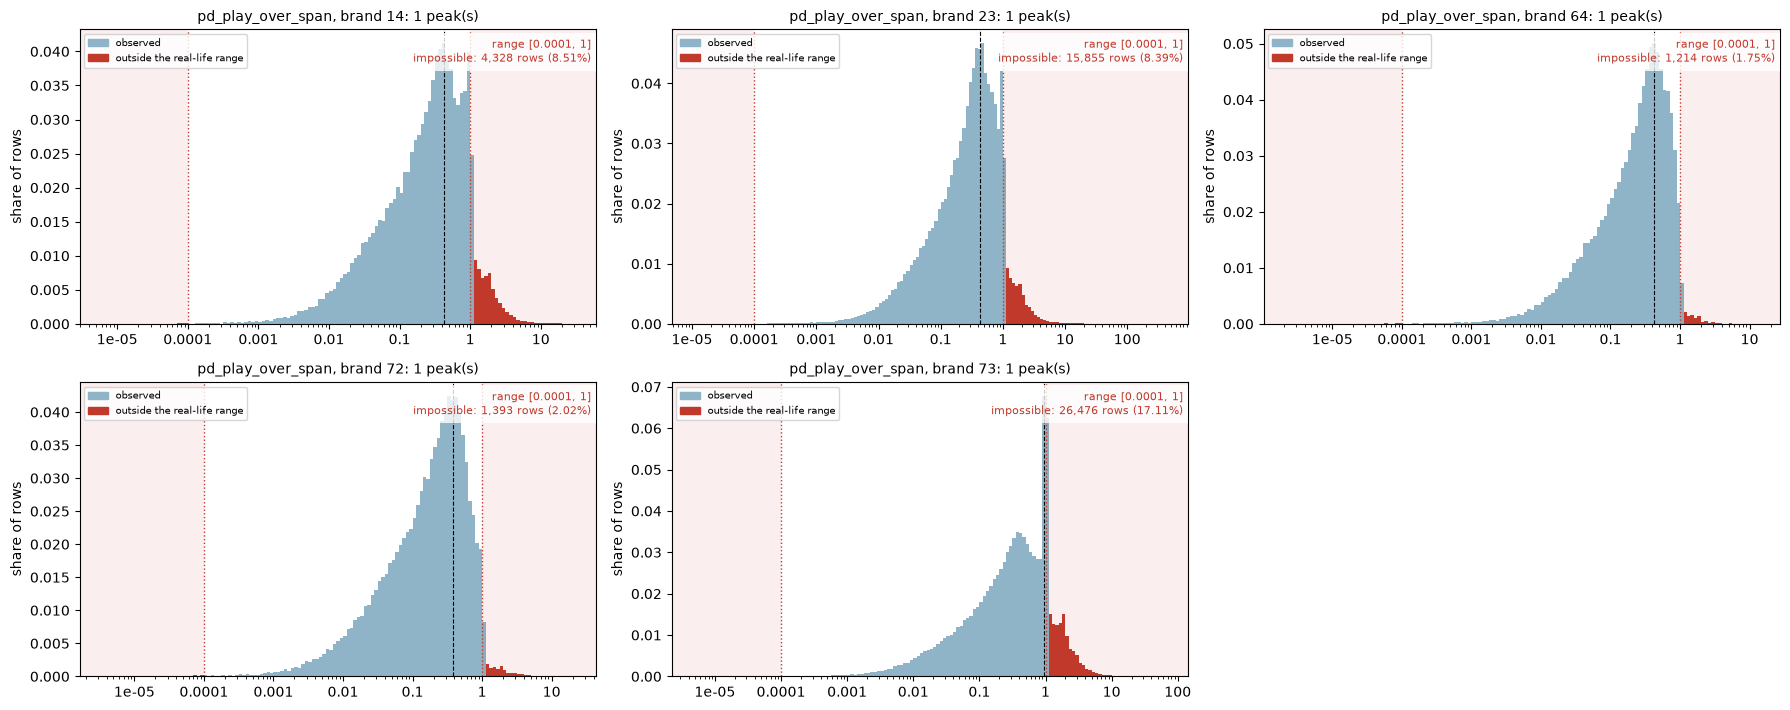

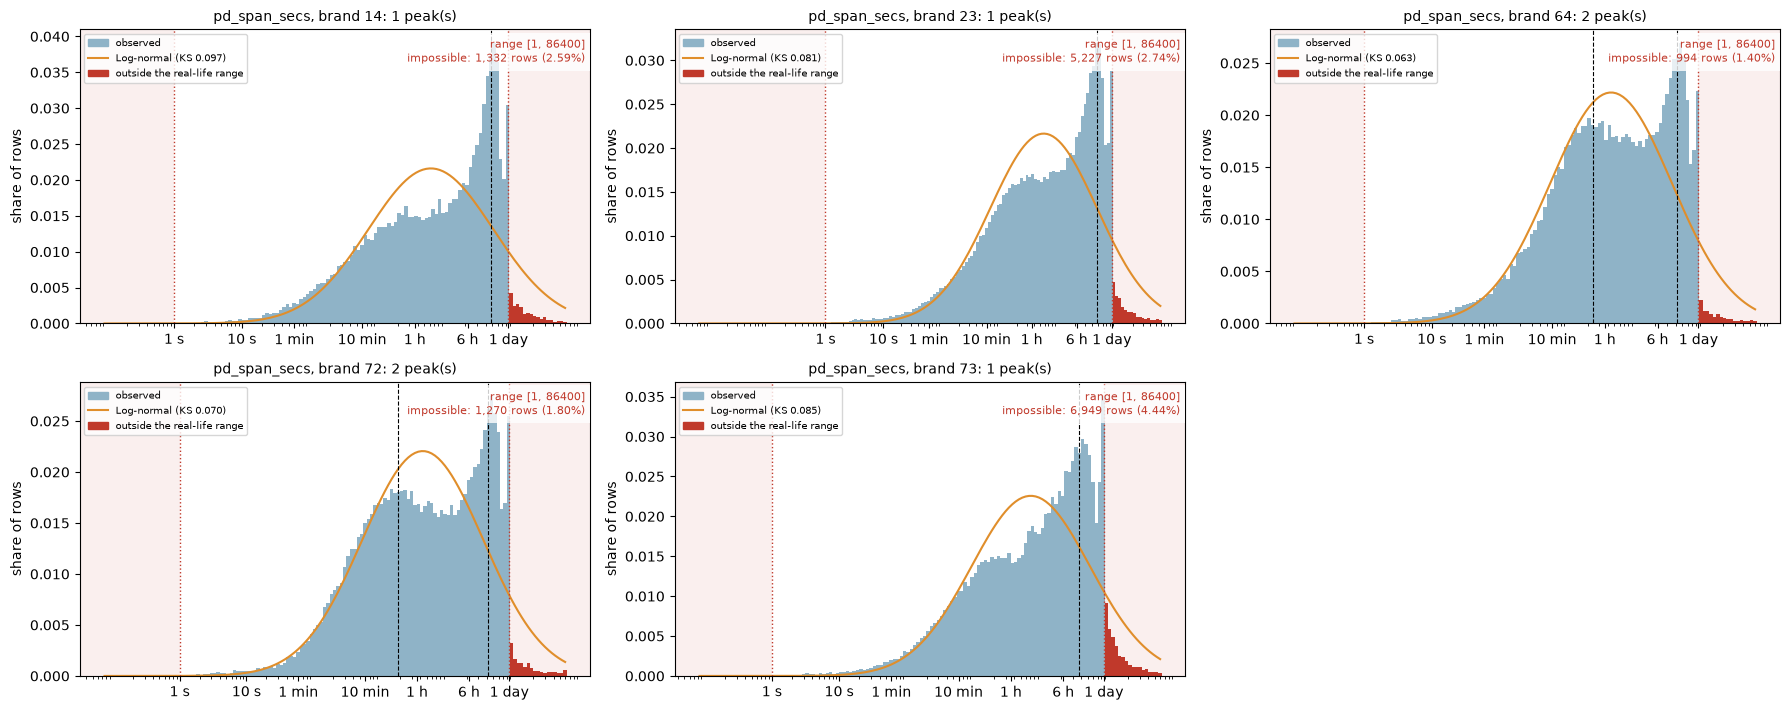

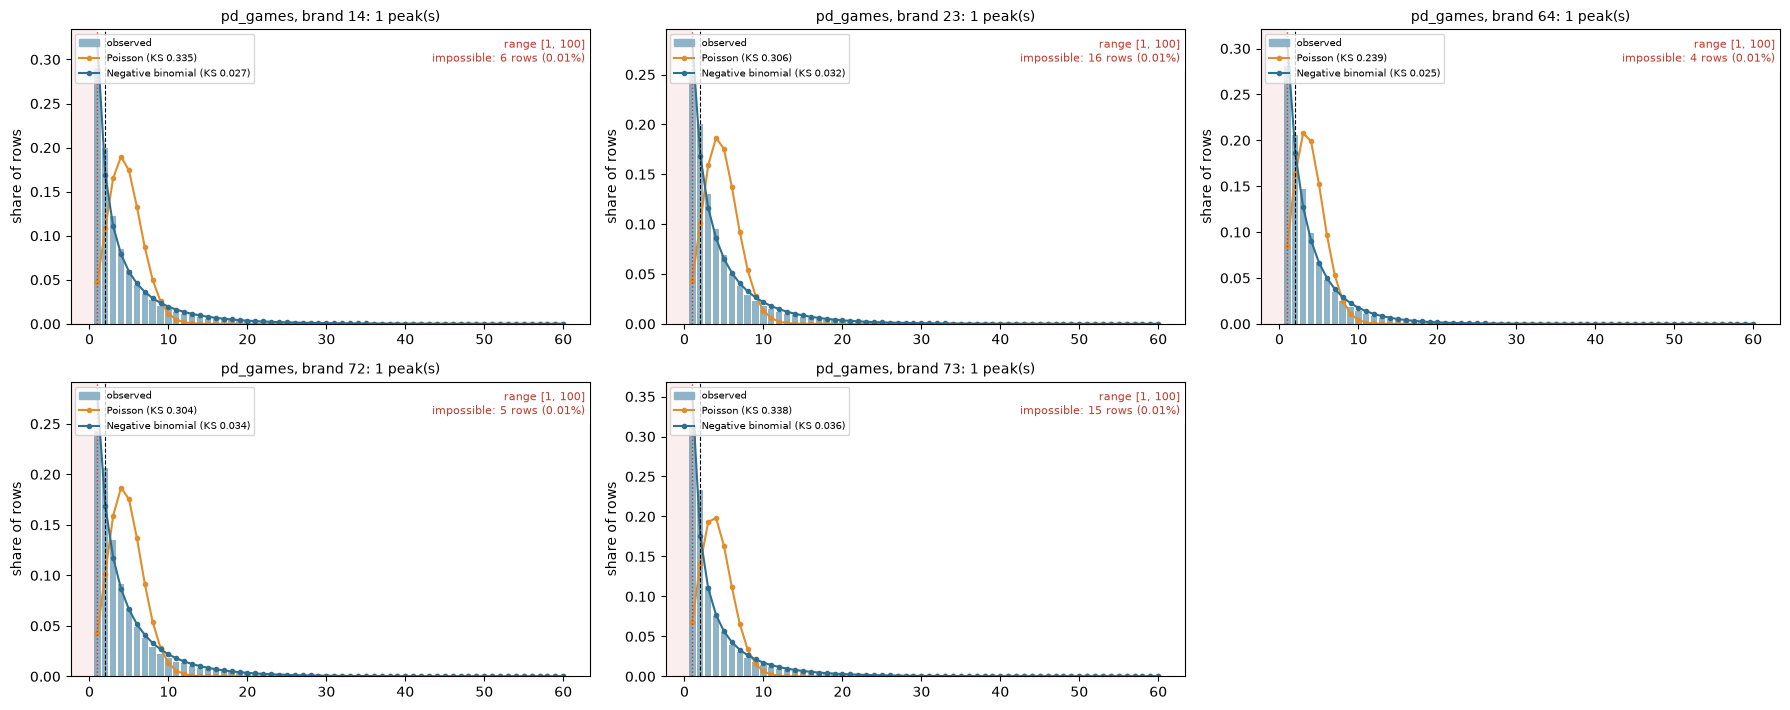

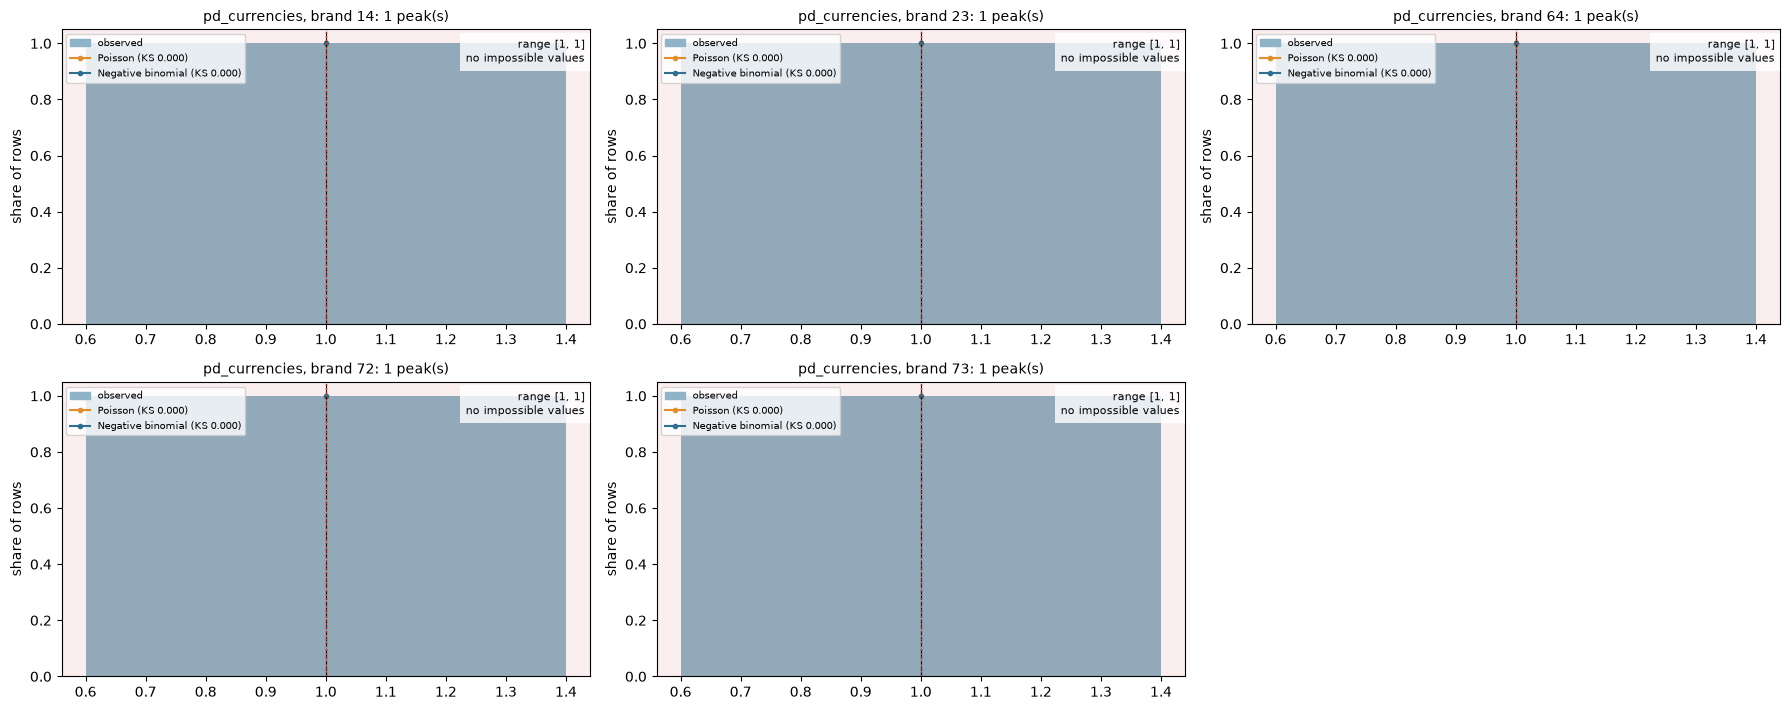

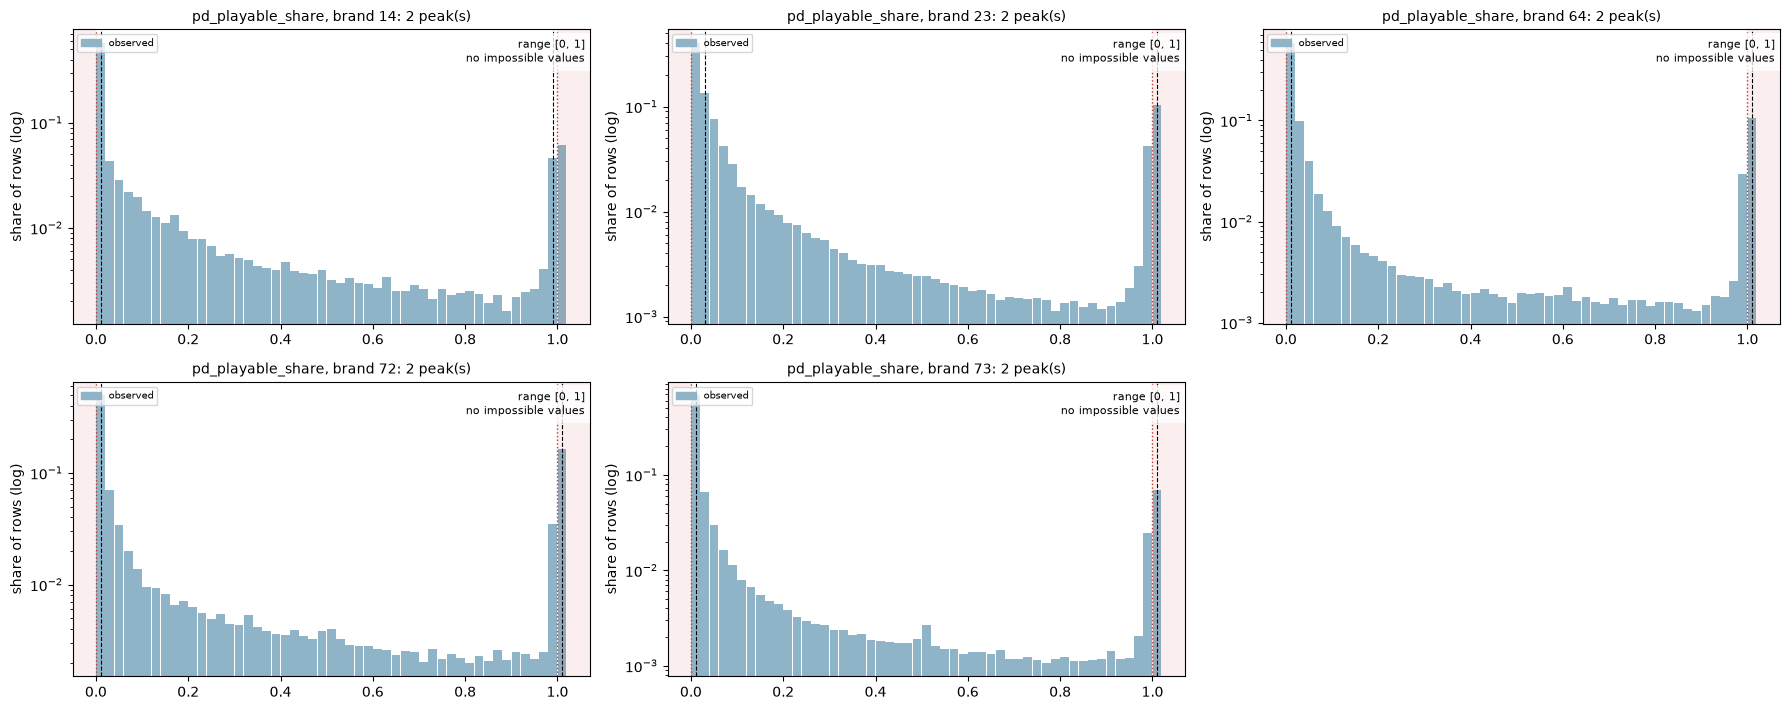

In [53]:
for name in METRICS:
    plots.brands(cfg, name)
    plt.show()

## 6. Impossible and Suspicious Values, per Day and Brand

Rules in `gaming.yaml`. **In every brand and every day** → a calculation error; **in one brand or some days** → a specific problem or real behaviour to check.

In [54]:
flags = pd.concat([audit.flags_by_day(cfg, t) for t in cfg["tables"]], ignore_index=True)
register = audit.flags_summary(flags, cfg)
display(register.round(3))

,metric,impossible if,suspicious if,rows,impossible,impossible %,days with impossible,suspicious,suspicious %,days with suspicious,brand 14: susp. %,brand 23: susp. %,brand 64: susp. %,brand 72: susp. %,brand 73: susp. %
0,pd_currencies,,x > 1,547133,0,0.000,0,0,0.000,0,0.000,0.000,0.000,0.000,0.000
1,pd_games,,x > 100,547133,0,0.000,0,46,0.008,26,0.012,0.008,0.005,0.007,0.010
2,pd_play_over_span,,x > 1,532640,0,0.000,0,49020,9.203,30,8.472,8.366,1.690,1.916,17.067
3,pd_play_secs,x > 86400,x > 57600 AND x <= 86400,532640,19468,3.655,30,8702,1.634,30,1.680,1.565,0.488,0.498,2.720
4,pd_span_secs,x > 86400,,540141,15475,2.865,30,0,0.000,0,0.000,0.000,0.000,0.000,0.000
5,row_avg_bet_eur,,x > 10000,2423692,0,0.000,0,54,0.002,28,0.000,0.005,0.000,0.000,0.001
6,row_bets,,x > 20000,2431214,0,0.000,0,33,0.001,22,0.000,0.002,0.000,0.002,0.002
7,row_fx_rate,x <= 0,,2447936,952,0.039,30,0,0.000,0,0.000,0.000,0.000,0.000,0.000
8,row_hold_pct,x > 1,x < -10,2423692,0,0.000,0,7496,0.309,30,0.306,0.300,0.250,0.284,0.362
9,row_max_win_eur,x < 0,x > 1000000,1798613,1,0.000,1,0,0.000,0,0.000,0.000,0.000,0.000,0.000


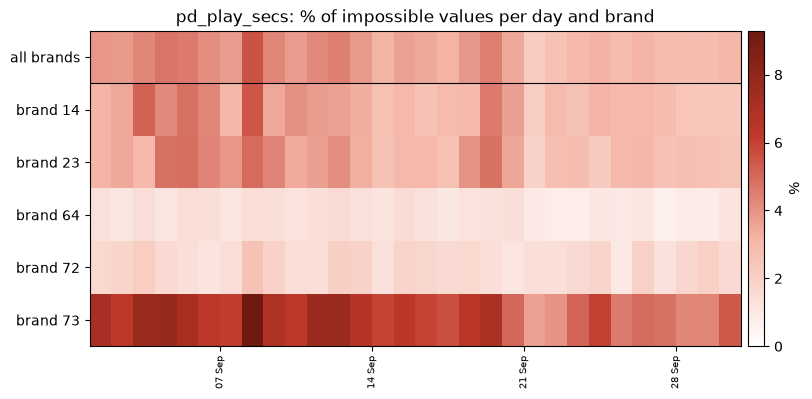

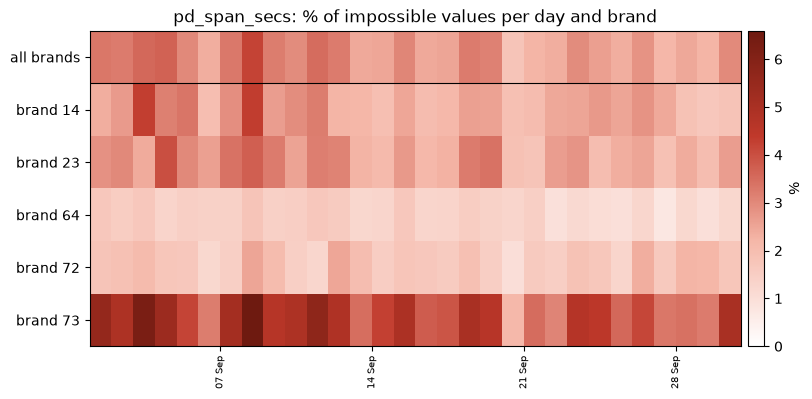

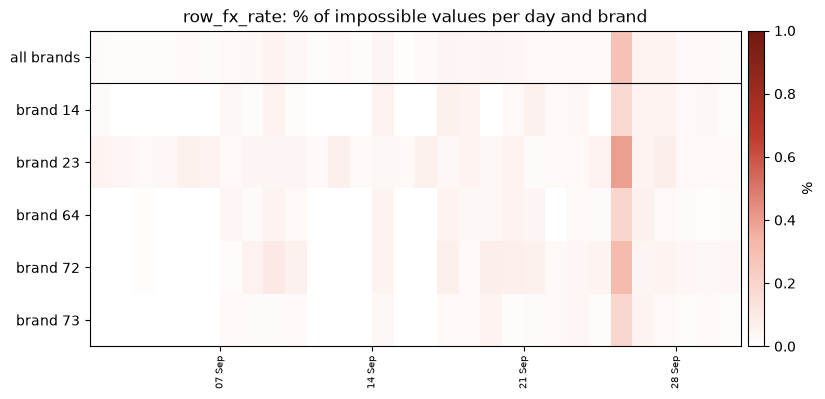

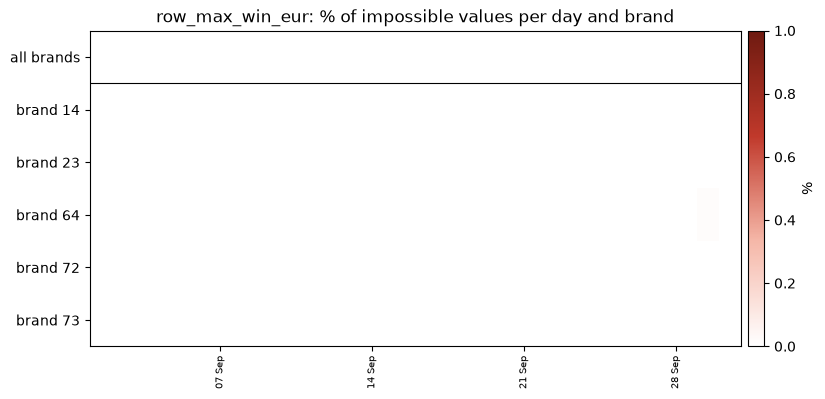

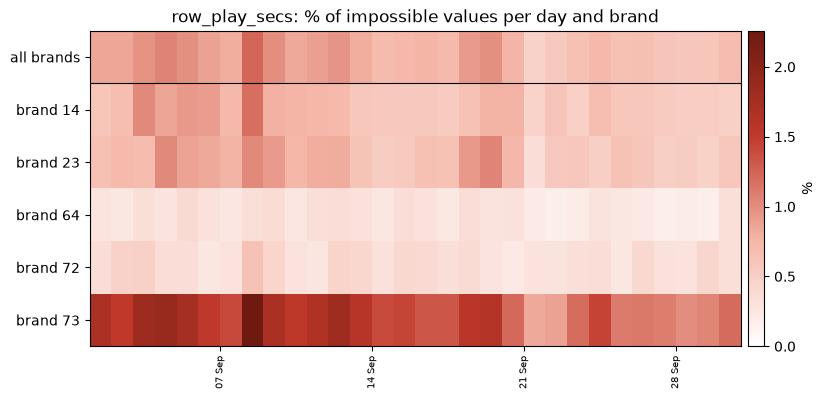

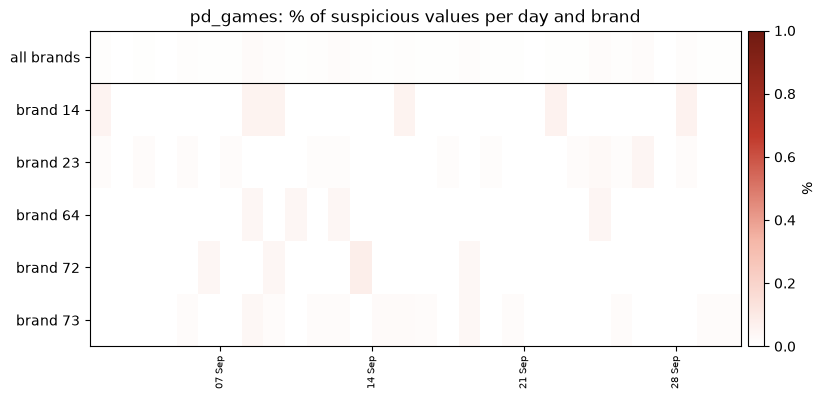

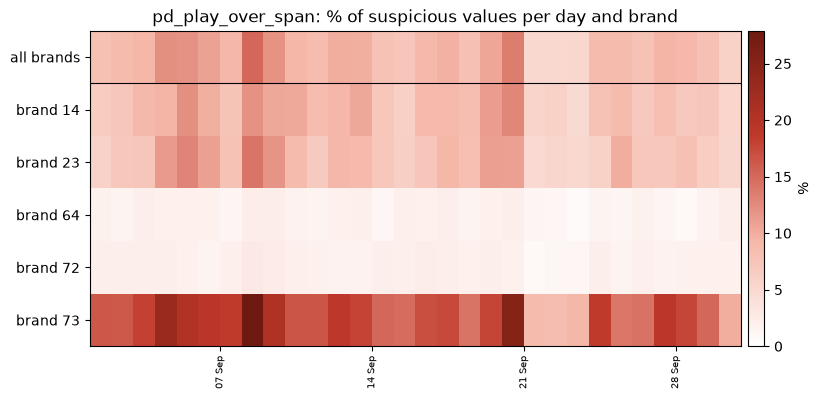

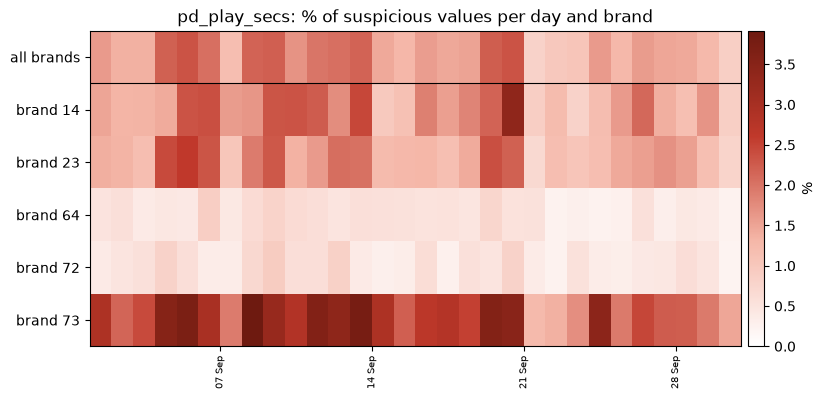

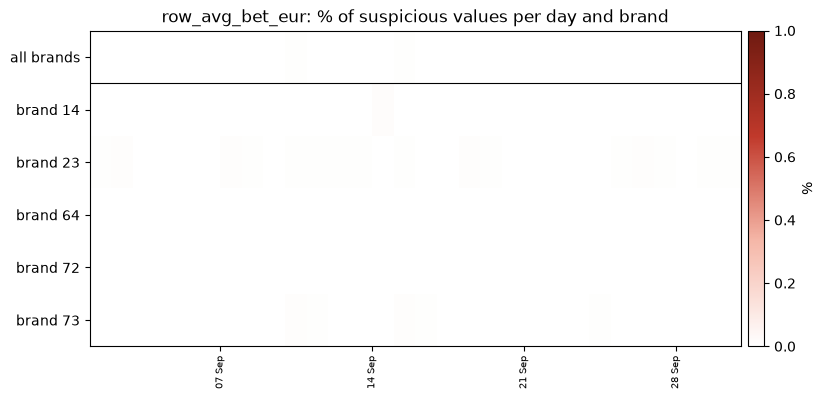

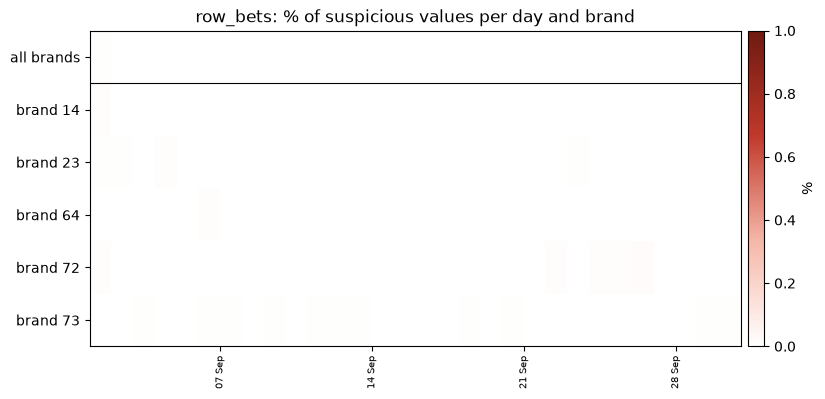

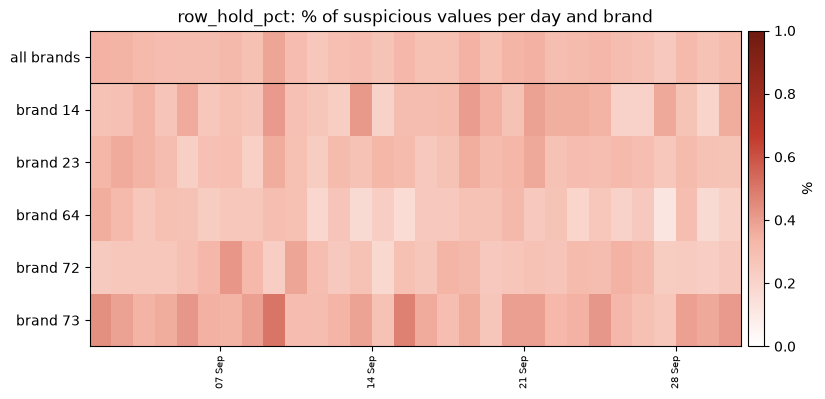

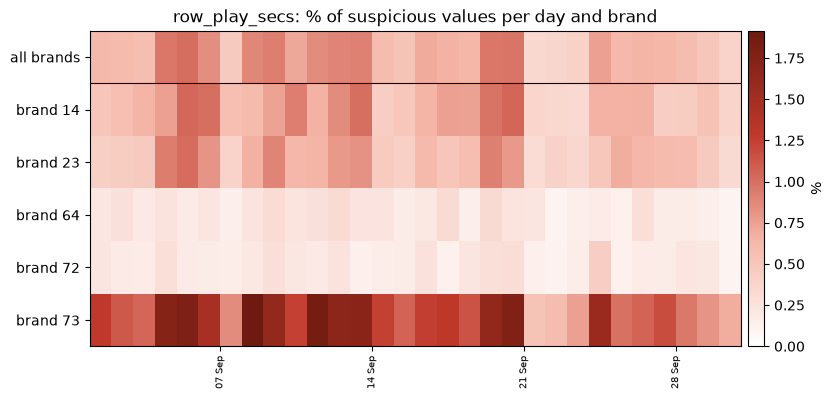

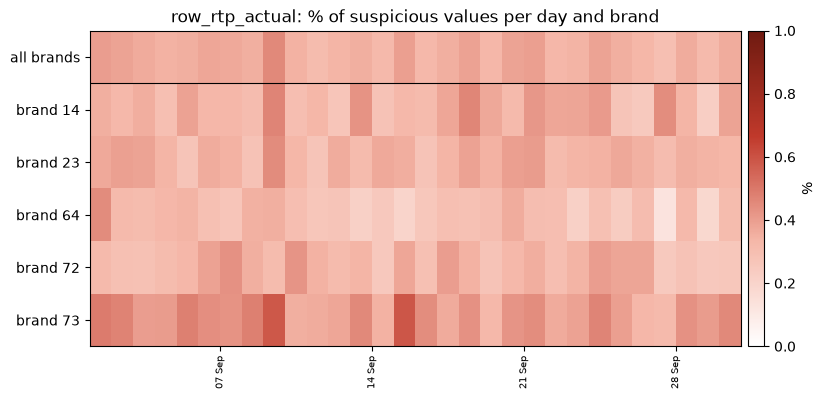

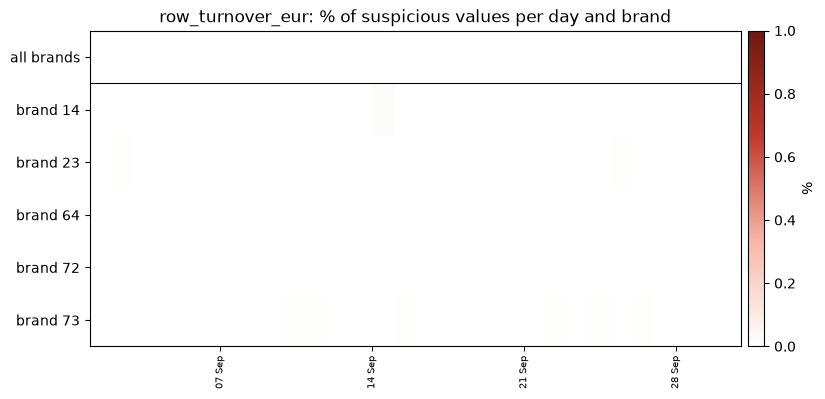

In [55]:
for kind in ("impossible", "suspicious"):
    view = flags.drop(columns=[c for c in ("impossible", "suspicious") if c != kind]).rename(columns={kind: "impossible"})
    for name in register.loc[register[kind] > 0, "metric"]:
        plots.by_day(view, name, title=f"{name}: % of {kind} values per day and brand")
        plt.show()

**Which values:** the most frequent flagged values, with their brand, currency and days.

In [56]:
for name in register.loc[(register["impossible"] + register["suspicious"]) > 0, "metric"]:
    print(name)
    display(audit.flagged_values(cfg, name))

pd_games


,value,kind,brand,currency,rows,first_day,last_day
0,161.0,suspicious,64,<NA>,2,2026-09-08,2026-09-24
1,111.0,suspicious,73,<NA>,2,2026-09-09,2026-09-29
2,109.0,suspicious,72,<NA>,2,2026-09-13,2026-09-18
3,104.0,suspicious,23,<NA>,2,2026-09-03,2026-09-24
4,102.0,suspicious,73,<NA>,2,2026-09-12,2026-09-15
5,200.0,suspicious,23,<NA>,1,2026-09-17,2026-09-17
6,157.0,suspicious,64,<NA>,1,2026-09-12,2026-09-12
7,149.0,suspicious,73,<NA>,1,2026-09-16,2026-09-16
8,148.0,suspicious,23,<NA>,1,2026-09-05,2026-09-05
9,147.0,suspicious,23,<NA>,1,2026-09-07,2026-09-07


pd_play_over_span


,value,kind,brand,currency,rows,first_day,last_day
0,1.0000,suspicious,73,<NA>,5406,2026-09-01,2026-09-30
1,1.0000,suspicious,23,<NA>,2068,2026-09-01,2026-09-30
2,1.0000,suspicious,14,<NA>,439,2026-09-01,2026-09-30
3,2.0000,suspicious,73,<NA>,215,2026-09-01,2026-09-25
4,1.0001,suspicious,73,<NA>,200,2026-09-01,2026-09-30
5,1.0000,suspicious,72,<NA>,180,2026-09-01,2026-09-30
6,1.0000,suspicious,64,<NA>,107,2026-09-01,2026-09-30
7,2.0000,suspicious,23,<NA>,76,2026-09-03,2026-09-19
8,1.0001,suspicious,23,<NA>,67,2026-09-01,2026-09-30
9,1.0002,suspicious,73,<NA>,44,2026-09-02,2026-09-30


pd_play_secs


...

,value,kind,brand,currency,rows,first_day,last_day
0,608219.910,impossible,23,<NA>,3,2026-09-07,2026-09-07
1,596851.410,impossible,23,<NA>,3,2026-09-20,2026-09-20
2,522210.753,impossible,23,<NA>,3,2026-09-01,2026-09-01
3,612847.226,impossible,72,<NA>,2,2026-09-15,2026-09-15
4,609832.033,impossible,72,<NA>,2,2026-09-04,2026-09-04
5,604867.617,impossible,23,<NA>,2,2026-09-14,2026-09-14
6,593880.237,impossible,23,<NA>,2,2026-09-27,2026-09-27
7,585119.937,impossible,73,<NA>,2,2026-09-27,2026-09-27
8,581008.803,impossible,23,<NA>,2,2026-09-15,2026-09-15
9,545189.960,impossible,23,<NA>,2,2026-09-26,2026-09-26


row_rtp_actual


,value,kind,brand,currency,rows,first_day,last_day
0,11.0000,suspicious,73,<NA>,20,2026-09-01,2026-09-30
1,13.0000,suspicious,73,<NA>,19,2026-09-01,2026-09-21
2,15.0000,suspicious,73,<NA>,12,2026-09-03,2026-09-29
3,16.0000,suspicious,73,<NA>,9,2026-09-01,2026-09-29
4,10.5000,suspicious,73,<NA>,9,2026-09-02,2026-09-30
5,10.8000,suspicious,73,<NA>,8,2026-09-08,2026-09-26
6,13.5000,suspicious,73,<NA>,7,2026-09-02,2026-09-25
7,12.0000,suspicious,73,<NA>,7,2026-09-01,2026-09-20
8,30.0000,suspicious,73,<NA>,6,2026-09-01,2026-09-25
9,20.0000,suspicious,73,<NA>,5,2026-09-03,2026-09-27


row_turnover_eur


,value,kind,brand,currency,rows,first_day,last_day
0,4.133681e+06,suspicious,14,TRY,1,2026-09-14,2026-09-14
1,3.960398e+06,suspicious,23,TRY,1,2026-09-02,2026-09-02
2,2.467903e+06,suspicious,23,TRY,1,2026-09-20,2026-09-20
3,2.310084e+06,suspicious,23,TRY,1,2026-09-27,2026-09-27
4,2.298446e+06,suspicious,23,TRY,1,2026-09-26,2026-09-26
5,2.221499e+06,suspicious,23,TRY,1,2026-09-12,2026-09-12
6,2.079682e+06,suspicious,23,TRY,1,2026-09-07,2026-09-07
7,2.054935e+06,suspicious,23,TRY,1,2026-09-29,2026-09-29
8,2.002392e+06,suspicious,73,EUR,1,2026-09-15,2026-09-15
9,2.001724e+06,suspicious,23,TRY,1,2026-09-08,2026-09-08


## 7. Categories

Rows per brand and value: data-quality status (`ok` excludes rows with a suspect FX rate), provisional FX rates, currencies, providers and source systems.

In [57]:
cats = gaming.categories(cfg)
for col, g in cats.groupby("col"):
    t = g.pivot_table(index="value", columns="brand_id", values="rows", aggfunc="sum", fill_value=0)
    t = (100 * t / t.sum()).round(2)
    print(col, "(% of rows per brand)")
    display(t.head(15))

currency (% of rows per brand)


brand_id,14,23,64,72,73
value,,,,,
AUD,0.0,0.00,0.0,0.00,0.04
CAD,0.0,0.00,0.0,0.00,0.00
EUR,0.0,0.00,0.0,12.33,38.79
INR,0.0,0.00,0.0,0.00,0.13
NZD,0.0,0.00,0.0,0.00,0.00
PLN,0.0,0.00,0.0,12.84,0.00
TRY,100.0,99.99,100.0,74.81,61.02
USD,0.0,0.00,0.0,0.00,0.00
USDT,0.0,0.01,0.0,0.01,0.02


dq_status (% of rows per brand)


brand_id,14,23,64,72,73
value,,,,,
fx_suspect,0.03,0.06,0.03,0.05,0.02
ok,99.97,99.94,99.97,99.95,99.98


fx_is_provisional (% of rows per brand)


brand_id,14,23,64,72,73
value,,,,,
false,99.18,98.8,99.14,99.31,99.45
true,0.82,1.2,0.86,0.69,0.55


provider_code (% of rows per brand)


brand_id,14,23,64,72,73
value,,,,,
34,3.47,1.75,2.32,1.59,3.38
37,0.64,0.30,0.26,0.77,0.70
39,0.02,0.00,0.00,0.01,0.01
40,0.02,0.01,0.01,0.01,0.04
46,6.36,4.95,4.18,8.68,11.51
48,3.12,2.08,2.92,7.03,3.47
50,0.00,0.00,4.45,2.76,0.00
51,0.25,0.14,0.13,0.20,0.27
54,1.36,0.40,0.35,0.88,0.66


source_system (% of rows per brand)


brand_id,14,23,64,72,73
value,,,,,
primus,100.0,0.0,100.0,100.0,100.0
secundus,0.0,100.0,0.0,0.0,0.0


## 8. Production Definition (ClickHouse)

The `CREATE` statement of the table and of every view that writes to it or reads from it. Metadata only, never data. Set `RUN_CH = True` (needs the tunnel and the credentials in `.env`).

In [58]:
if RUN_CH:
    definition = gaming.clickhouse_definition()
    display(definition[["database", "name", "engine"]])
    for _, r in definition.iterrows():
        print(f"---- {r['database']}.{r['name']} ({r['engine']})")
        print(r["create_table_query"][:4000])

## 9. Findings

September 2026, brands 14, 23, 64, 72 and 73: 2.45 million rows, 547,133 player-days.

### What is correct

- **Keys:** no duplicated rows, no key with two versions, no player in two brands or two currencies on the same day.
- **FX conversion:** every `*_eur` column equals the native amount × `fx_rate_to_eur` (100%).
- **Totals:** `turnover_eur` = stake of **all three wallets**, including playable bonus (100%); `payout_eur` = wins of all wallets; `ggr_eur` = turnover − payout; `net_position_eur` = −GGR; `tax_eur`, `win_rate` and `avg_bet_eur` follow their formula (100%).
- **No negative wins** in September (they exist in the history, see section 2).
- **One currency per brand mostly:** brands 14, 23 and 64 play only in TRY; brand 72 in TRY, PLN and EUR; brand 73 in TRY and EUR.

### What is wrong

| Problem | How much | Where |
|---|---|---|
| **`play_secs` over 24 h in one row** (one game, one day) | 0.8% of the rows | Every brand, every day; worst in brand 73 |
| **`play_secs` over 24 h in one player-day** | 3.7% of the player-days | Every brand; worst in 73 |
| **Play time longer than the time between the first and the last play** | 9.2% of the player-days | Brand 73: 17% |
| **Last play on a later day than `event_date`** | 1.6% of the rows; 2.9% of the player-days span over 24 h | Every brand; worst in 73 |
| **The workbook rule for `bets` is wrong** (the column is correct) | the sum of `bet_count_*` counts twice a bet paid from two wallets (22% of the rows) | Every brand |
| **`real_ggr_eur` is not real stake − real wins** | 21% of the rows | Every brand |
| **`loyalty_points_delta` scale not documented** | median 26 million points per row; not an error until the scale is known | Every brand |
| **FX rate of 0** (`dq_status = fx_suspect`) | 952 rows (0.04%) | Every brand |
| **FX rate from a later date** | 0.3% of the rows | Every brand |
| **Schema different from the workbook** | 15 columns planned but not deployed (`platform_id`, `cashout_*`, `balance_*`, `win_count_*`); 12 deployed but not in the workbook (`turnover_eur`, `ggr_eur`, `hold_pct`…) | — |

### What it means

- **Play time:** the same pattern as in the signals table. Games played at the same time are added up, and some rows cover more than one day. `play_secs` should not be used as it is.
- **The churn model is safe on the main inputs:** active days, recency and stake come from `wagered_*` and `event_date`, which are correct. `turnover_eur` includes playable bonus, so the official active day must use `wagered_real + wagered_released_bonus`, as the pipeline does.

### Confirmed with the new checks and with ClickHouse

- **`hold_pct` and `rtp_actual` are ratios, not percents:** `hold_pct = ggr / turnover` and `rtp_actual = payout / turnover = 1 − hold_pct` (100%). The name says "pct" but the value goes up to 1.
- **`real_ggr_eur` counts released bonus as real money:** (real + released bonus stake) − (real + released bonus wins) (100%), as in the ClickHouse definition. It is not an error; the workbook does not say it.
- **`bets` counts each bet once:** `max(bet_count_*) <= bets <= sum` (100% and 99.6%), and `bets = sum` in the rows with one wallet (99.85%). The sum of `bet_count_*` counts a bet paid from two wallets twice, so the workbook rule is wrong, not the column.
- **`event_date` is the UTC day of the first play** (100%). A first run said 9%: the DuckDB session was in Madrid time, so a play after 22:00 UTC moved to the next day. The connection is now in UTC.
- **Two versions of the table in ClickHouse:** `medallion.gld_player_gaming_daily` (the one in the lake, audited here) and `gld.player_gaming_daily` (the new design of the workbook, with `platform_id`, `win_count_*`, `cashout_*`). The 15 "workbook only" columns exist in the new table.
- **The sort key of the lake table has no `currency` and no `brand_id`:** two rows of the same player, game and day in two currencies could be merged into one. It does not happen today (0 players with two currencies on a day), but nothing prevents it. The new table adds both to the key.
- **`hold_pct`, `rtp_actual`, `win_rate`, `avg_bet_eur` and `loyalty_points_delta` are calculated before the insert,** not in ClickHouse, so their formula is not visible there. The scale of `loyalty_points_delta` is still open.
